# 04 — Results: tables and figures for the paper

Turns the saved training output into the artifacts the paper reports. This
notebook **only aggregates what is on disk** — it never trains, and it never
invents a number that the parquets do not contain.

Training is still running, so every section reads what exists and says plainly
what is missing. A table built from a partial grid is labelled as partial.

**Inputs**
- `results/*.parquet` — one row per (disease, definition, h, test_year, model)
  with AUROC, AUPRC, and the test-fold size
- `predictions/*.parquet` — one row per municipality-month per model, with the
  true label and the predicted probability
- `data/master/labels.parquet` — the 16 outbreak labels, used to recover the
  municipality's outbreak state in the *current* month

**Outputs** — CSV tables under `<train dir>/tables/`, figures under `figuras/`.

## Section 0 — Setup

**Which training directory.** `data/train/` holds the first run, whose
`target_year` was computed as `ano + (mes == 12)` — correct at h = 1 but wrong
for every longer horizon, which put months that predict into the test year in the
training set. `data/train/` is the corrected re-run. Everything below reads
the corrected one; point `TRAIN_DIR` at the old folder only to reproduce the
earlier numbers deliberately.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
MASTER_DIR = PROJECT_ROOT / "data" / "master"

# The corrected run. See the markdown above before changing this.
TRAIN_DIR = PROJECT_ROOT / "data" / "train"

RESULTS_DIR = TRAIN_DIR / "results"
PRED_DIR = TRAIN_DIR / "predictions"
TABLES_DIR = TRAIN_DIR / "tables"
FIG_DIR = PROJECT_ROOT / "figuras"
for d in (TABLES_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

TEST_YEARS = [2022, 2023, 2024]
COMBO = re.compile(r"^(\w+?)_(\w+)_h(\d+)\.parquet$")

# --- What finished training, and what has not ---
def available_combos(folder):
    found = {}
    for path in sorted(folder.glob("*.parquet")):
        m = COMBO.match(path.name)
        if m:
            found[(m.group(1), m.group(2), int(m.group(3)))] = path
    return found

results_on_disk = available_combos(RESULTS_DIR)
preds_on_disk = available_combos(PRED_DIR)
print(f"Reading from: {TRAIN_DIR.relative_to(PROJECT_ROOT)}")
print(f"Result files:      {len(results_on_disk)} of 96 combos")
print(f"Prediction files:  {len(preds_on_disk)}")

by_disease = {}
for (disease, definition, h) in results_on_disk:
    by_disease.setdefault(disease, set()).add((definition, h))
print("\nCombos finished, by disease (24 = complete: 4 definitions x 6 horizons):")
for disease in ("dengue", "zika", "chikungunya", "fa"):
    n = len(by_disease.get(disease, ()))
    state = "COMPLETE" if n == 24 else f"partial ({n}/24)" if n else "not started"
    print(f"  {disease:<12} {state}")

# --- Load every result row that exists ---
results = pd.concat([pd.read_parquet(p) for p in results_on_disk.values()],
                    ignore_index=True) if results_on_disk else pd.DataFrame()
print(f"\nResult rows loaded: {len(results):,}")
print(f"Models present: {sorted(results['model'].unique())}")

labels = pd.read_parquet(MASTER_DIR / "labels.parquet")
print(f"Labels: {labels.shape}")

Reading from: data/train
Result files:      90 of 96 combos
Prediction files:  90

Combos finished, by disease (24 = complete: 4 definitions x 6 horizons):
  dengue       COMPLETE
  zika         COMPLETE
  chikungunya  COMPLETE
  fa           partial (18/24)

Result rows loaded: 1,620
Models present: ['climatology', 'lgbm', 'logreg', 'persistence', 'rf', 'xgb']


Labels: (89010, 19)


### Helpers

`prevalence` comes from the folds themselves (`n_pos / n_test` summed over the
three test years), not from the whole base — the reference for AUPRC has to be
the prevalence of the set the model was scored on.

**Lift = AUPRC / prevalence.** For a rare disease the raw AUPRC is small by
construction; a model with AUPRC 0.17 where outbreaks are 0.28% of months is far
from a failure. Reporting AUPRC without its prevalence invites exactly that
misreading, so the two always travel together here.

In [2]:
MODEL_LABELS = {
    "persistence": "Persistence", "climatology": "Climatology",
    "logreg": "Logistic regression", "ebm": "EBM",
    "rf": "Random Forest", "xgb": "XGBoost", "lgbm": "LightGBM",
}
MODEL_ORDER = ["persistence", "climatology", "logreg", "ebm", "rf", "xgb", "lgbm"]

def combo_rows(disease, definition, h=1):
    """Result rows for one combo, or an empty frame if it has not trained yet."""
    if results.empty:
        return pd.DataFrame()
    return results[(results["disease"] == disease)
                   & (results["definition"] == definition)
                   & (results["h"] == h)]

def prevalence_of(rows):
    """Positive rate across the test folds the models were actually scored on."""
    fold = rows.drop_duplicates(subset=["test_year"])[["n_pos", "n_test"]]
    return fold["n_pos"].sum() / fold["n_test"].sum() if len(fold) else np.nan

def performance_table(disease, definition, h=1):
    """AUROC, AUPRC and lift per model, averaged over the test years."""
    rows = combo_rows(disease, definition, h)
    if rows.empty:
        print(f"  MISSING: {disease}/{definition}/h{h} has not trained yet")
        return None, np.nan
    prev = prevalence_of(rows)
    table = (rows.groupby("model")[["auroc", "auprc"]].mean()
             .reindex([m for m in MODEL_ORDER if m in set(rows["model"])]))
    table["lift"] = table["auprc"] / prev
    table.index = [MODEL_LABELS.get(m, m) for m in table.index]
    table = table.round({"auroc": 3, "auprc": 3, "lift": 1})
    folds = sorted(rows["test_year"].unique())
    print(f"  {disease}/{definition}/h{h}: prevalence {prev:.3f}, "
          f"test years {folds}"
          + ("" if folds == TEST_YEARS else "   <- PARTIAL, not all folds present"))
    return table, prev

## Section 1 — Global performance by model (dengue, inc100)

Every model scored on the same folds, averaged over the three test years. This is
the paper's headline table.

Read AUPRC against the prevalence line, not against 1.0: a model guessing at
random scores exactly the prevalence, so the lift column is what says how much
signal there is.

In [3]:
table3, prev_inc100 = performance_table("dengue", "inc100", h=1)
if table3 is not None:
    print(f"\nGlobal performance: dengue, inc100, h=1 (prevalence {prev_inc100:.3f})")
    print(table3.to_string())
    table3.to_csv(TABLES_DIR / "table3_global_dengue_inc100.csv")
    print(f"\nSaved: {TABLES_DIR.name}/table3_global_dengue_inc100.csv")
table3

  dengue/inc100/h1: prevalence 0.253, test years [np.int64(2022), np.int64(2023), np.int64(2024)]

Global performance: dengue, inc100, h=1 (prevalence 0.253)
                     auroc  auprc  lift
Persistence          0.825  0.612   2.4
Climatology          0.768  0.498   2.0
Logistic regression  0.859  0.664   2.6
Random Forest        0.914  0.806   3.2
XGBoost              0.919  0.816   3.2
LightGBM             0.918  0.817   3.2

Saved: tables/table3_global_dengue_inc100.csv


,auroc,auprc,lift
Persistence,0.825,0.612,2.4
Climatology,0.768,0.498,2.0
Logistic regression,0.859,0.664,2.6
Random Forest,0.914,0.806,3.2
XGBoost,0.919,0.816,3.2
LightGBM,0.918,0.817,3.2


## Section 2 — Global performance by model (dengue, endemic channel)

The same table under the endemic-channel definition, where an outbreak is a
departure from the municipality's own history for that month rather than a fixed
incidence level.

Watch the climatology row in particular. A seasonal baseline predicts what
normally happens in that month — which is precisely what the endemic channel
subtracts out — so it is blind to this kind of outbreak by construction, not by
poor fitting.

In [4]:
table5, prev_canal = performance_table("dengue", "canal", h=1)
if table5 is not None:
    print(f"\nGlobal performance: dengue, endemic channel, h=1 "
          f"(prevalence {prev_canal:.3f})")
    print(table5.to_string())
    table5.to_csv(TABLES_DIR / "table5_global_dengue_canal.csv")
    print(f"\nSaved: {TABLES_DIR.name}/table5_global_dengue_canal.csv")
table5

  dengue/canal/h1: prevalence 0.265, test years [np.int64(2022), np.int64(2023), np.int64(2024)]

Global performance: dengue, endemic channel, h=1 (prevalence 0.265)
                     auroc  auprc  lift
Persistence          0.804  0.579   2.2
Climatology          0.532  0.294   1.1
Logistic regression  0.739  0.504   1.9
Random Forest        0.840  0.658   2.5
XGBoost              0.835  0.633   2.4
LightGBM             0.828  0.628   2.4

Saved: tables/table5_global_dengue_canal.csv


,auroc,auprc,lift
Persistence,0.804,0.579,2.2
Climatology,0.532,0.294,1.1
Logistic regression,0.739,0.504,1.9
Random Forest,0.840,0.658,2.5
XGBoost,0.835,0.633,2.4
LightGBM,0.828,0.628,2.4


## Section 3 — Onset versus continuation

**This is the paper's central claim, so the definitions matter more here than
anywhere else.** Aggregate metrics fuse two tasks of very different difficulty:
telling that an outbreak already under way will continue, and telling that a calm
municipality is about to enter one. Only the second anticipates anything.

The predictions carry the outbreak state at the **predicted** month (`y_true`).
What they do not carry is the state at the month the prediction was *made from*.
We recover it from the labels, joined on `(cod_ibge, ano, mes)` — the row's own
month — and call it `surto_atual`.

With both states in hand, every test row falls into one of four groups:

| Group | `surto_atual` | `y_true` | What it means |
|---|---|---|---|
| **Onset** | 0 | 1 | calm municipality entering an outbreak — *the task that matters* |
| **Continuation** | 1 | 1 | already in outbreak and staying there |
| Calm, stays calm | 0 | 0 | where a false alarm costs something |
| Outbreak ends | 1 | 0 | leaving an outbreak |

The metrics reported below, all at a **fixed decision threshold of 0.5**:

- **Onset recall** — of the calm→outbreak transitions, how many were alerted.
- **Continuation recall** — of the ongoing outbreaks, how many were alerted.
- **Precision restricted to calm municipalities** — of the alerts raised where the
  municipality was calm, how many turned into an outbreak. This is *not* the
  global precision: the global number is inflated by alerts on municipalities that
  were already in outbreak, which are easy and anticipate nothing.
- **False-alarm rate in calm months** — of calm months that stayed calm, how many
  got an alert.

The climatology baseline is measured on the **same slice** — same disease, same
definition, same horizon, same rows. Mixing definitions here once produced a
badly wrong baseline number in an earlier version of this work, so the slice is
passed explicitly and never aggregated away.

In [5]:
DISEASE, DEFINITION, HORIZON = "dengue", "inc100", 1
THRESHOLD = 0.5

pred_path = PRED_DIR / f"{DISEASE}_{DEFINITION}_h{HORIZON}.parquet"
onset_table = None          # set below; stays None if this combo has not trained
if not pred_path.exists():
    print(f"MISSING: {pred_path.name} — this section needs it; skipping.")
else:
    preds = pd.read_parquet(pred_path)
    print(f"Predictions: {preds.shape}  models: {sorted(preds['model'].unique())}")

    # Outbreak state in the row's OWN month, from the labels.
    label_col = f"{DISEASE}_{DEFINITION}"
    current = (labels[["cod_ibge", "ano", "mes", label_col]]
               .rename(columns={label_col: "surto_atual"}))
    preds = preds.merge(current, on=["cod_ibge", "ano", "mes"], how="left",
                        validate="m:1")
    missing_state = preds["surto_atual"].isna().sum()
    print(f"Rows with no current-month label: {missing_state:,} "
          f"({missing_state / len(preds):.2%})")
    preds = preds.dropna(subset=["surto_atual"])
    preds["surto_atual"] = preds["surto_atual"].astype(int)

def phase_metrics(frame, threshold=THRESHOLD):
    """Split one model's predictions into the four phases and score each."""
    alert = frame["proba"] >= threshold
    calm = frame["surto_atual"] == 0
    ongoing = frame["surto_atual"] == 1
    onset = calm & (frame["y_true"] == 1)
    continuation = ongoing & (frame["y_true"] == 1)
    calm_stays = calm & (frame["y_true"] == 0)

    alerts_in_calm = alert & calm
    return {
        "n_onset": int(onset.sum()),
        "n_continuation": int(continuation.sum()),
        "recall_onset": alert[onset].mean() if onset.any() else np.nan,
        "recall_continuation": alert[continuation].mean() if continuation.any() else np.nan,
        "recall_global": alert[frame["y_true"] == 1].mean(),
        "precision_global": frame.loc[alert, "y_true"].mean() if alert.any() else np.nan,
        "precision_in_calm": frame.loc[alerts_in_calm, "y_true"].mean() if alerts_in_calm.any() else np.nan,
        "false_alarm_calm": alert[calm_stays].mean() if calm_stays.any() else np.nan,
    }

Predictions: (139320, 10)  models: ['climatology', 'lgbm', 'logreg', 'persistence', 'rf', 'xgb']
Rows with no current-month label: 0 (0.00%)


In [6]:
if pred_path.exists():
    rows = []
    for model in ("rf", "lgbm", "xgb", "climatology", "persistence"):
        sub = preds[preds["model"] == model]
        if sub.empty:
            print(f"  {model}: not in this prediction file, skipped")
            continue
        rows.append({"model": MODEL_LABELS.get(model, model), **phase_metrics(sub)})

    onset_table = pd.DataFrame(rows).set_index("model")
    show = onset_table[["recall_onset", "recall_continuation", "recall_global",
                        "precision_global", "precision_in_calm", "false_alarm_calm"]]
    print(f"\nPhase-separated performance: {DISEASE}/{DEFINITION}/h{HORIZON}, "
          f"threshold {THRESHOLD}")
    print(f"Onset events: {onset_table['n_onset'].iloc[0]:,}   "
          f"continuation months: {onset_table['n_continuation'].iloc[0]:,}")
    print((show * 100).round(1).to_string())

    onset_table.to_csv(TABLES_DIR / "table_onset_vs_continuation.csv")
    print(f"\nSaved: {TABLES_DIR.name}/table_onset_vs_continuation.csv")

    # The contrast the paper is built on, stated in one place.
    if "Random Forest" in onset_table.index:
        rf_row = onset_table.loc["Random Forest"]
        print("\n" + "=" * 66)
        print("What the aggregate metric hides:")
        print(f"  Continuation recall : {rf_row['recall_continuation']:.1%}   (easy: already in outbreak)")
        print(f"  Onset recall        : {rf_row['recall_onset']:.1%}   (the task that anticipates)")
        print(f"  Gap                 : {abs(rf_row['recall_continuation']-rf_row['recall_onset'])*100:.1f} points")
        print(f"  Precision, all rows : {rf_row['precision_global']:.1%}")
        print(f"  Precision, calm only: {rf_row['precision_in_calm']:.1%}   (the honest number)")
        if "Climatology" in onset_table.index:
            clim = onset_table.loc["Climatology"]
            print(f"\n  Onset recall  RF {rf_row['recall_onset']:.1%}  vs  "
                  f"climatology {clim['recall_onset']:.1%}"
                  f"   (+{(rf_row['recall_onset']-clim['recall_onset'])*100:.1f} points)")
            print(f"  False alarm   RF {rf_row['false_alarm_calm']:.1%}  vs  "
                  f"climatology {clim['false_alarm_calm']:.1%}")
        print("=" * 66)
onset_table


Phase-separated performance: dengue/inc100/h1, threshold 0.5
Onset events: 1,513   continuation months: 4,370
               recall_onset  recall_continuation  recall_global  precision_global  precision_in_calm  false_alarm_calm
model                                                                                                                 
Random Forest          46.5                 89.1           78.1              68.2               32.8               9.1
LightGBM               39.7                 84.3           72.8              73.8               36.8               6.5
XGBoost                47.4                 86.4           76.4              70.4               34.8               8.4
Climatology             6.8                 16.4           14.0              62.9               22.3               2.2
Persistence             0.0                100.0           74.3              75.7                NaN               0.0

Saved: tables/table_onset_vs_continuation.csv

What the

,n_onset,n_continuation,recall_onset,recall_continuation,recall_global,precision_global,precision_in_calm,false_alarm_calm
model,,,,,,,,
Random Forest,1513,4370,0.465301,0.890618,0.781234,0.681798,0.327899,0.090561
LightGBM,1513,4370,0.396563,0.843249,0.728370,0.738030,0.368324,0.064579
XGBoost,1513,4370,0.473893,0.864073,0.763726,0.704453,0.347889,0.084348
Climatology,1513,4370,0.068077,0.164302,0.139555,0.628637,0.223427,0.022468
Persistence,1513,4370,0.000000,1.000000,0.742818,0.756972,NaN,0.000000


### The same trade-off across every threshold

A single threshold is one point on a curve. Sweeping it shows the choice the
manager actually faces: alert more and catch more onsets at the cost of more false
alarms, or alert less and trust each alert more.

Two pairs are plotted. **All months** is the aggregate view — the flattering one.
**Calm municipalities only** restricts to alerts that anticipate something, and
its precision starts far lower. The distance between the two panels is the
paper's argument in a picture.

Saved: figuras/threshold_tradeoff.pdf and .png


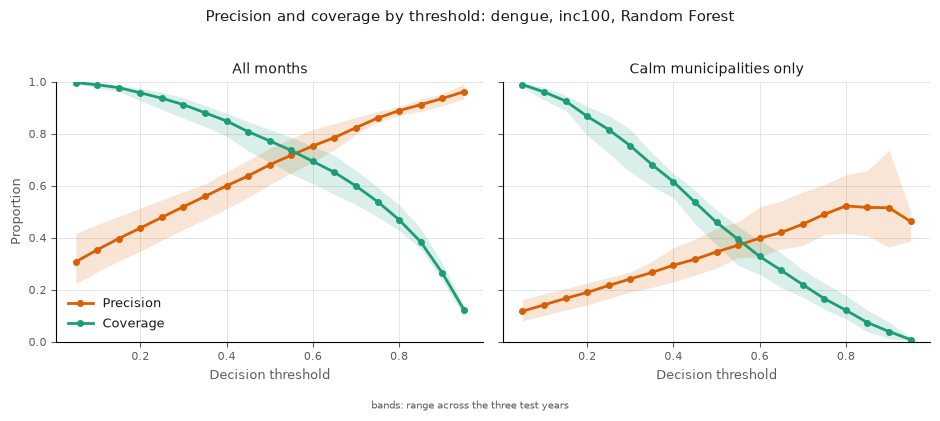

In [7]:
import matplotlib.pyplot as plt

# Colours carry identity only; both pairs were checked for colour-vision
# separation (deutan dE 11.6, normal dE 25.7) rather than assumed to be safe.
C_PRECISION, C_COVERAGE = "#d95f02", "#1b9e77"
INK, MUTED, GRID = "#1a1a1a", "#5c5c5c", "#d9d9d9"

def sweep(frame, thresholds, restrict_to_calm):
    """Precision and coverage across thresholds, optionally only where calm.

    Computed inside each test year and then aggregated, never pooled: the line is
    the mean over the three folds and the band is the range between the lowest and
    the highest fold. Three folds is far too few for a confidence interval to mean
    anything, but the observed range is exactly what the data supports — and
    without it the curve claims a steadiness it does not have.
    """
    out = []
    scope = frame[frame["surto_atual"] == 0] if restrict_to_calm else frame
    for t in thresholds:
        per_fold = []
        for _, fold in scope.groupby("test_year"):
            alert = fold["proba"] >= t
            positives = fold["y_true"] == 1
            if not alert.any() or not positives.any():
                continue
            per_fold.append((fold.loc[alert, "y_true"].mean(), alert[positives].mean()))
        if not per_fold:
            continue
        a = np.array(per_fold)
        mean, lo, hi = a.mean(axis=0), a.min(axis=0), a.max(axis=0)
        out.append({"threshold": t,
                    "precision": mean[0], "precision_min": lo[0], "precision_max": hi[0],
                    "coverage": mean[1], "coverage_min": lo[1], "coverage_max": hi[1]})
    return pd.DataFrame(out)

if pred_path.exists() and (preds["model"] == "rf").any():
    rf_preds = preds[preds["model"] == "rf"]
    grid = np.arange(0.05, 0.96, 0.05)
    panels = [("All months", sweep(rf_preds, grid, False)),
              ("Calm municipalities only", sweep(rf_preds, grid, True))]

    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
    for ax, (title, curve) in zip(axes, panels):
        # Band = lowest to highest of the three test years.
        ax.fill_between(curve["threshold"], curve["precision_min"],
                        curve["precision_max"], color=C_PRECISION, alpha=0.16, lw=0)
        ax.fill_between(curve["threshold"], curve["coverage_min"],
                        curve["coverage_max"], color=C_COVERAGE, alpha=0.16, lw=0)
        ax.plot(curve["threshold"], curve["precision"], color=C_PRECISION,
                linewidth=2, marker="o", markersize=4, label="Precision")
        ax.plot(curve["threshold"], curve["coverage"], color=C_COVERAGE,
                linewidth=2, marker="o", markersize=4, label="Coverage")
        ax.set_title(title, fontsize=10, color=INK)
        ax.set_xlabel("Decision threshold", fontsize=9, color=MUTED)
        ax.set_ylim(0, 1)
        ax.grid(True, color=GRID, linewidth=0.6, alpha=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.tick_params(colors=MUTED, labelsize=8)
    axes[0].set_ylabel("Proportion", fontsize=9, color=MUTED)
    axes[0].legend(frameon=False, fontsize=9, labelcolor=INK)
    fig.text(0.5, -0.03, "bands: range across the three test years",
             ha="center", fontsize=7.5, color=MUTED)
    fig.suptitle(f"Precision and coverage by threshold: {DISEASE}, {DEFINITION}, "
                 f"Random Forest", fontsize=11, color=INK, y=1.02)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"threshold_tradeoff.{ext}", bbox_inches="tight", dpi=200)
    print(f"Saved: figuras/threshold_tradeoff.pdf and .png")
    plt.show()

## Section 4 — Degradation by forecast horizon

One model per horizon, trained by direct forecasting: the features stay frozen at
month *t* and only the target moves to *t + h*. So a longer horizon does not give
the model more information to work with — it gives it the same information about a
month further away.

The fold split follows the **year of the target**, not of the observation, at every
horizon. That distinction is what keeps a row whose outbreak falls inside the test
year out of the training set.

In [8]:
HORIZONS = [1, 2, 3, 4, 5, 6]
rows, missing = [], []
for h in HORIZONS:
    combo = combo_rows("dengue", "inc100", h)
    rf_rows = combo[combo["model"] == "rf"] if not combo.empty else combo
    if rf_rows.empty:
        missing.append(h)
        continue
    prev = prevalence_of(combo)
    rows.append({"h": h,
                 "auroc": rf_rows["auroc"].mean(),
                 "auroc_min": rf_rows["auroc"].min(), "auroc_max": rf_rows["auroc"].max(),
                 "auprc": rf_rows["auprc"].mean(),
                 "auprc_min": rf_rows["auprc"].min(), "auprc_max": rf_rows["auprc"].max(),
                 "lift": rf_rows["auprc"].mean() / prev,
                 "prevalence": prev,
                 "test_years": len(rf_rows)})

if missing:
    print(f"MISSING horizons (not trained yet): {missing}")

horizon_table = pd.DataFrame(rows).set_index("h") if rows else None
if horizon_table is not None:
    print("\nHorizon degradation: dengue, inc100, Random Forest")
    print(horizon_table.round(3).to_string())
    horizon_table.to_csv(TABLES_DIR / "table6_horizon_degradation.csv")
    print(f"\nSaved: {TABLES_DIR.name}/table6_horizon_degradation.csv")
horizon_table


Horizon degradation: dengue, inc100, Random Forest
   auroc  auroc_min  auroc_max  auprc  auprc_min  auprc_max   lift  prevalence  test_years
h                                                                                         
1  0.914      0.880      0.937  0.806      0.793      0.822  3.180       0.253           3
2  0.878      0.826      0.912  0.711      0.708      0.717  2.806       0.253           3
3  0.856      0.788      0.894  0.645      0.621      0.690  2.547       0.253           3
4  0.843      0.766      0.883  0.609      0.549      0.679  2.404       0.253           3
5  0.825      0.732      0.875  0.572      0.498      0.638  2.257       0.253           3
6  0.812      0.717      0.870  0.552      0.475      0.592  2.178       0.253           3

Saved: tables/table6_horizon_degradation.csv


,auroc,auroc_min,auroc_max,auprc,auprc_min,auprc_max,lift,prevalence,test_years
h,,,,,,,,,
1,0.914235,0.879893,0.937489,0.805686,0.793355,0.822095,3.180014,0.253359,3
2,0.877593,0.825539,0.912393,0.710894,0.707887,0.716898,2.805876,0.253359,3
3,0.855683,0.787557,0.893853,0.645342,0.621333,0.689936,2.547144,0.253359,3
4,0.843415,0.765726,0.882548,0.609077,0.548731,0.679210,2.404006,0.253359,3
5,0.824859,0.731623,0.874988,0.571952,0.498108,0.637569,2.257473,0.253359,3
6,0.812463,0.716771,0.870065,0.551755,0.475307,0.592121,2.177759,0.253359,3


Saved: figuras/horizon_degradation.pdf and .png


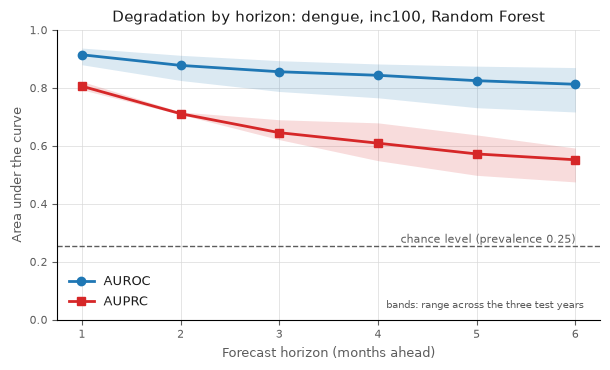

In [9]:
# --- Figure: the degradation curve ---
# Two series, one axis (both are areas under a curve, same 0-1 scale) — never a
# second y-axis. Blue/red checked for colour-vision separation (protan dE 21.1).
C_AUROC, C_AUPRC = "#1f77b4", "#d62728"

if horizon_table is not None and len(horizon_table) > 1:
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    # Band = lowest to highest of the three test years, the same convention used
    # in every figure here.
    ax.fill_between(horizon_table.index, horizon_table["auroc_min"],
                    horizon_table["auroc_max"], color=C_AUROC, alpha=0.16, lw=0)
    ax.fill_between(horizon_table.index, horizon_table["auprc_min"],
                    horizon_table["auprc_max"], color=C_AUPRC, alpha=0.16, lw=0)
    ax.plot(horizon_table.index, horizon_table["auroc"], color=C_AUROC,
            linewidth=2, marker="o", markersize=6, label="AUROC")
    ax.plot(horizon_table.index, horizon_table["auprc"], color=C_AUPRC,
            linewidth=2, marker="s", markersize=6, label="AUPRC")

    # The prevalence line is the reference AUPRC would reach by chance; without it
    # the red curve looks like a collapse rather than a controlled decline.
    prev_line = horizon_table["prevalence"].mean()
    ax.axhline(prev_line, color=MUTED, linewidth=1, linestyle="--")
    ax.text(horizon_table.index.max(), prev_line + 0.012,
            f"chance level (prevalence {prev_line:.2f})",
            ha="right", fontsize=8, color=MUTED)

    ax.set_xlabel("Forecast horizon (months ahead)", fontsize=9, color=MUTED)
    ax.set_ylabel("Area under the curve", fontsize=9, color=MUTED)
    ax.set_ylim(0, 1)
    ax.set_xticks(list(horizon_table.index))
    ax.grid(True, color=GRID, linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK)
    ax.annotate("bands: range across the three test years", (0.97, 0.04),
                xycoords="axes fraction", ha="right", fontsize=7.5, color=MUTED)
    ax.set_title("Degradation by horizon: dengue, inc100, Random Forest",
                 fontsize=11, color=INK)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"horizon_degradation.{ext}", bbox_inches="tight", dpi=200)
    print("Saved: figuras/horizon_degradation.pdf and .png")
    plt.show()
else:
    print("Not enough horizons trained yet to draw the curve.")

## Section 5 — Agreement between the four outbreak definitions

Cohen's kappa corrects the observed agreement for the agreement two labellers
would reach by chance. It matters here because most municipality-months are not
outbreaks, so raw agreement is high no matter what the definitions do — kappa
strips that trivial agreement out.

Computed on the labels themselves, over the test years, so it describes the
definitions and not any model.

In [10]:
from sklearn.metrics import cohen_kappa_score
from itertools import combinations

DEFINITIONS = ["inc100", "inc300", "canal", "zscore"]
disease = "dengue"

in_test = labels["ano"].isin(TEST_YEARS)
kappa = pd.DataFrame(index=DEFINITIONS, columns=DEFINITIONS, dtype=float)
raw_agreement = {}
for a, b in combinations(DEFINITIONS, 2):
    ya, yb = labels.loc[in_test, f"{disease}_{a}"], labels.loc[in_test, f"{disease}_{b}"]
    kappa.loc[a, b] = kappa.loc[b, a] = round(cohen_kappa_score(ya, yb), 3)
    raw_agreement[(a, b)] = (ya == yb).mean()
for d in DEFINITIONS:
    kappa.loc[d, d] = 1.0

print(f"Cohen's kappa between definitions — {disease}, test years {TEST_YEARS}")
print(kappa.to_string())
print("\nRaw agreement, for contrast (inflated by the shared non-outbreak months):")
for (a, b), value in raw_agreement.items():
    print(f"  {a:>7} vs {b:<7} {value:.1%} raw   vs kappa {kappa.loc[a, b]:+.3f}")

kappa.to_csv(TABLES_DIR / "table_kappa_definitions.csv")
print(f"\nSaved: {TABLES_DIR.name}/table_kappa_definitions.csv")
kappa

Cohen's kappa between definitions — dengue, test years [2022, 2023, 2024]
        inc100  inc300  canal  zscore
inc100   1.000   0.701  0.597   0.574
inc300   0.701   1.000  0.500   0.494
canal    0.597   0.500  1.000   0.915
zscore   0.574   0.494  0.915   1.000

Raw agreement, for contrast (inflated by the shared non-outbreak months):
   inc100 vs inc300  90.1% raw   vs kappa +0.701
   inc100 vs canal   84.5% raw   vs kappa +0.597
   inc100 vs zscore  84.3% raw   vs kappa +0.574
   inc300 vs canal   83.1% raw   vs kappa +0.500
   inc300 vs zscore  84.0% raw   vs kappa +0.494
    canal vs zscore  96.8% raw   vs kappa +0.915

Saved: tables/table_kappa_definitions.csv


,inc100,inc300,canal,zscore
inc100,1.000,0.701,0.597,0.574
inc300,0.701,1.000,0.500,0.494
canal,0.597,0.500,1.000,0.915
zscore,0.574,0.494,0.915,1.000


## Section 6 — Random Forest across diseases and definitions

Whether one definition serves every disease. Diseases still training are listed
rather than silently dropped, and a combination with no outbreak in the test years
is reported as such — an empty cell there is a property of the disease, not a
failure of the model.

In [11]:
DISEASES = ["dengue", "zika", "chikungunya", "fa"]
PAIR_DEFS = ["inc100", "canal"]

rows, not_trained = [], []
for disease in DISEASES:
    for definition in PAIR_DEFS:
        combo = combo_rows(disease, definition, h=1)
        if combo.empty:
            not_trained.append(f"{disease}/{definition}")
            rows.append({"disease": disease, "definition": definition,
                         "prevalence": np.nan, "auroc": np.nan,
                         "auprc": np.nan, "lift": np.nan, "status": "not trained yet"})
            continue
        rf_rows = combo[combo["model"] == "rf"]
        prev = prevalence_of(combo)
        if rf_rows.empty or prev == 0 or np.isnan(prev):
            rows.append({"disease": disease, "definition": definition,
                         "prevalence": prev, "auroc": np.nan, "auprc": np.nan,
                         "lift": np.nan, "status": "no outbreak in test years"})
            continue
        rows.append({"disease": disease, "definition": definition,
                     "prevalence": prev,
                     "auroc": rf_rows["auroc"].mean(),
                     "auprc": rf_rows["auprc"].mean(),
                     "lift": rf_rows["auprc"].mean() / prev,
                     "status": "ok"})

disease_table = pd.DataFrame(rows).set_index(["disease", "definition"])
print("Random Forest by disease and definition (h=1, mean over test years)")
print(disease_table.round(3).to_string())
if not_trained:
    print(f"\nStill training: {', '.join(not_trained)}")

disease_table.to_csv(TABLES_DIR / "table4_disease_definition.csv")
print(f"\nSaved: {TABLES_DIR.name}/table4_disease_definition.csv")
disease_table

Random Forest by disease and definition (h=1, mean over test years)
                        prevalence  auroc  auprc    lift                     status
disease     definition                                                             
dengue      inc100           0.253  0.914  0.806   3.180                         ok
            canal            0.265  0.840  0.658   2.480                         ok
zika        inc100           0.000    NaN    NaN     NaN  no outbreak in test years
            canal            0.003  0.975  0.134  47.805                         ok
chikungunya inc100           0.003  0.822  0.126  41.140                         ok
            canal            0.012  0.924  0.320  25.801                         ok
fa          inc100           0.000    NaN    NaN     NaN  no outbreak in test years
            canal            0.000    NaN    NaN     NaN  no outbreak in test years

Saved: tables/table4_disease_definition.csv


prevalence     auroc     auprc       lift  \
disease     definition                                              
dengue      inc100        0.253359  0.914235  0.805686   3.180014   
            canal         0.265202  0.839911  0.657722   2.480074   
zika        inc100        0.000000       NaN       NaN        NaN   
            canal         0.002799  0.974971  0.133821  47.804915   
chikungunya inc100        0.003058  0.822461  0.125795  41.140227   
            canal         0.012403  0.923894  0.320011  25.800899   
fa          inc100        0.000000       NaN       NaN        NaN   
            canal         0.000000       NaN       NaN        NaN   

                                           status  
disease     definition                             
dengue      inc100                             ok  
            canal                              ok  
zika        inc100      no outbreak in test years  
            canal                              ok  
chikungunya inc100                             ok  
            canal                              ok  
fa          inc100      no outbreak in test years  
            canal       no outbreak in test years

## Section 7 — The cohort and its labels

Table I of the paper. Everything here is counted from `municipio_mes.parquet` and
`labels.parquet`, not from the training output, so it describes the data before any
model sees it.

The second table is the one that decides what the rest of the paper can claim. A
definition with no positive month in 2022–2024 cannot be scored at all: AUROC is
undefined when every test label is zero. Reporting that as a blank rather than
quietly dropping it is the honest form, because the blank is itself a result —
it says the definition does not fire for that disease at this scale.


In [12]:
master = pd.read_parquet(MASTER_DIR / "municipio_mes.parquet")

first = master.loc[master["ano"] == master["ano"].min(), "mes"].min()
last = master.loc[master["ano"] == master["ano"].max(), "mes"].max()

cohort = pd.DataFrame([
    ("Municipalities",        f"{master['cod_ibge'].nunique():,}"),
    ("Months",                f"{master.groupby(['ano', 'mes']).ngroups:,}"),
    ("Period",                f"{master['ano'].min()}-{first:02d} to {master['ano'].max()}-{last:02d}"),
    ("Municipality-months",   f"{len(master):,}"),
    ("Columns in the master", f"{master.shape[1]:,}"),
    ("Diseases",              f"{len(DISEASES)}"),
    ("Outbreak definitions",  f"{len(DEFINITIONS)}"),
    ("Population, smallest",  f"{master['pop_residente'].min():,.0f}"),
    ("Population, largest",   f"{master['pop_residente'].max():,.0f}"),
    ("Test years",            ", ".join(str(y) for y in TEST_YEARS)),
], columns=["", "value"]).set_index("")

print("Table I — the cohort")
print(cohort.to_string())
cohort.to_csv(TABLES_DIR / "table1_cohort.csv")
print(f"\n  Saved: tables/table1_cohort.csv")


Table I — the cohort
                                    value
                                         
Municipalities                        645
Months                                138
Period                 2015-01 to 2026-06
Municipality-months                89,010
Columns in the master                  83
Diseases                                4
Outbreak definitions                    4
Population, smallest                  836
Population, largest            12,396,372
Test years               2022, 2023, 2024

  Saved: tables/table1_cohort.csv


In [13]:
# Prevalence of every label, over the whole series and over the test years only.
rows = []
for disease in DISEASES:
    for definition in DEFINITIONS:
        col = f"{disease}_{definition}"
        if col not in labels.columns:
            continue
        series = labels[col]
        test = labels.loc[labels["ano"].isin(TEST_YEARS), col]
        n_all, n_test = series.notna().sum(), test.notna().sum()
        pos_all, pos_test = int((series == 1).sum()), int((test == 1).sum())
        # Municipalities that ever had one, and how concentrated the label is.
        ever = labels.loc[series == 1, "cod_ibge"].nunique()
        rows.append({
            "disease": disease, "definition": definition,
            "pos_all": pos_all,
            "prev_all_%": 100 * pos_all / n_all if n_all else np.nan,
            "pos_test": pos_test,
            "prev_test_%": 100 * pos_test / n_test if n_test else np.nan,
            "municipalities_ever": ever,
        })

prevalence_table = pd.DataFrame(rows).set_index(["disease", "definition"])
print("Label prevalence — whole series and test years")
print(prevalence_table.round(3).to_string())
prevalence_table.to_csv(TABLES_DIR / "table2_label_prevalence.csv")
print(f"\n  Saved: tables/table2_label_prevalence.csv")


Label prevalence — whole series and test years
                        pos_all  prev_all_%  pos_test  prev_test_%  municipalities_ever
disease     definition                                                                 
dengue      inc100        14218      15.973      5883       25.336                  644
            inc300         8204       9.217      3595       15.482                  631
            canal         12881      14.471      6158       26.520                  645
            zscore        11262      12.653      5422       23.351                  645
zika        inc100           13       0.015         0        0.000                    8
            inc300            3       0.003         0        0.000                    2
            canal           400       0.449        65        0.280                   77
            zscore          339       0.381        49        0.211                   77
chikungunya inc100          116       0.130        71        0.306       

In [14]:
# Which disease x definition pairs can actually be scored, and why not when not.
scored = (results.dropna(subset=["auroc"])
          .groupby(["disease", "definition"])["h"].nunique())
trained = results.groupby(["disease", "definition"])["h"].nunique()

rows = []
for disease in DISEASES:
    for definition in DEFINITIONS:
        key = (disease, definition)
        pos_test = int(prevalence_table.loc[key, "pos_test"]) if key in prevalence_table.index else 0
        pos_all = int(prevalence_table.loc[key, "pos_all"]) if key in prevalence_table.index else 0
        n_trained, n_scored = int(trained.get(key, 0)), int(scored.get(key, 0))
        if pos_all == 0:
            verdict = "no positive month anywhere in the series"
        elif pos_test == 0:
            verdict = "positives exist, but none in the test years"
        elif n_scored == 0:
            verdict = "not trained"
        elif n_scored < 6:
            verdict = f"scored at {n_scored} of 6 horizons"
        else:
            verdict = "evaluable"
        rows.append({"disease": disease, "definition": definition,
                     "pos_all": pos_all, "pos_test": pos_test,
                     "horizons_trained": n_trained, "horizons_scored": n_scored,
                     "verdict": verdict})

evaluability = pd.DataFrame(rows).set_index(["disease", "definition"])
print("Evaluability of each disease x definition pair")
print(evaluability.to_string())
evaluability.to_csv(TABLES_DIR / "table_evaluability.csv")

n_ok = (evaluability["verdict"] == "evaluable").sum()
print(f"\n  {n_ok} of {len(evaluability)} pairs are evaluable at all six horizons.")
print(f"  Saved: tables/table_evaluability.csv")


Evaluability of each disease x definition pair
                        pos_all  pos_test  horizons_trained  horizons_scored                                      verdict
disease     definition                                                                                                   
dengue      inc100        14218      5883                 6                6                                    evaluable
            inc300         8204      3595                 6                6                                    evaluable
            canal         12881      6158                 6                6                                    evaluable
            zscore        11262      5422                 6                6                                    evaluable
zika        inc100           13         0                 6                0  positives exist, but none in the test years
            inc300            3         0                 6                0  positives exist, but 

## Section 8 — A shared visual language for the figures

Six models appear in every figure below, so they get one fixed colour assignment
used everywhere: a reader who learns the colours in one figure keeps them in the
next. The four learned models carry hue; the two baselines are grey and dashed,
which says *reference line* before the legend is read.

The four hues were checked with a colour-vision simulator rather than assumed
safe — worst adjacent separation dE 11.0 under deuteranopia and 25.8 under normal
vision, and all four clear 3:1 contrast against white, so the figures survive
photocopying and colour-blind readers alike.


In [15]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Hue = the four learned models. Grey + dash = the two reference baselines.
MODEL_COLORS = {
    "rf": "#0072B2", "xgb": "#D55E00", "lgbm": "#009E73", "logreg": "#5D3A9B",
    "persistence": "#6e6e6e", "climatology": "#a8a8a8",
}
MODEL_DASH = {"persistence": (0, (5, 2)), "climatology": (0, (1, 1.5))}
INK, MUTED, GRID = "#1a1a1a", "#5c5c5c", "#d9d9d9"

PLOT_ORDER = ["rf", "xgb", "lgbm", "logreg", "persistence", "climatology"]

def style_axes(ax, ylabel=None, xlabel=None):
    """One recessive grid, no box, muted ticks — applied to every axis below."""
    ax.grid(True, color=GRID, linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9, color=MUTED)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9, color=MUTED)
    return ax

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight", dpi=200)
    print(f"  Saved: figuras/{name}.pdf and .png")

def model_line_kwargs(model):
    kw = {"color": MODEL_COLORS.get(model, MUTED), "linewidth": 2}
    if model in MODEL_DASH:
        kw["linestyle"] = MODEL_DASH[model]
        kw["linewidth"] = 1.6
    return kw

print("Palette fixed for every figure below:")
for m in PLOT_ORDER:
    print(f"  {MODEL_LABELS[m]:<20} {MODEL_COLORS[m]}"
          + ("  (dashed baseline)" if m in MODEL_DASH else ""))


Palette fixed for every figure below:
  Random Forest        #0072B2
  XGBoost              #D55E00
  LightGBM             #009E73
  Logistic regression  #5D3A9B
  Persistence          #6e6e6e  (dashed baseline)
  Climatology          #a8a8a8  (dashed baseline)


## Section 9 — Stability across the three test years

Every table so far averages 2022, 2023 and 2024. An average hides the question a
reviewer will ask first: does the model hold up in a year unlike the others? 2024
matters here because it followed the largest dengue season in the series, so the
outbreak base rate itself moved.

A model whose AUROC swings by a tenth between folds is not the same finding as one
that holds within a hundredth, even when the two report the same mean.


In [16]:
def by_year_table(disease, definition, h=1):
    rows = combo_rows(disease, definition, h).dropna(subset=["auroc"])
    if rows.empty:
        print(f"  MISSING: {disease}/{definition}/h{h}")
        return None
    wide = rows.pivot_table(index="model", columns="test_year", values="auroc")
    wide = wide.reindex([m for m in MODEL_ORDER if m in wide.index])
    wide["mean"] = wide[TEST_YEARS].mean(axis=1)
    wide["spread"] = wide[TEST_YEARS].max(axis=1) - wide[TEST_YEARS].min(axis=1)
    wide.index = [MODEL_LABELS.get(m, m) for m in wide.index]
    return wide.round(3)

stability = {}
for definition in ("inc100", "canal"):
    tbl = by_year_table("dengue", definition)
    if tbl is None:
        continue
    stability[definition] = tbl
    prev_by_year = (combo_rows("dengue", definition, 1)
                    .drop_duplicates("test_year").set_index("test_year"))
    print(f"AUROC by test year: dengue, {definition}, h=1")
    print("  outbreak base rate: "
          + "  ".join(f"{y} {prev_by_year.loc[y, 'n_pos'] / prev_by_year.loc[y, 'n_test']:.1%}"
                      for y in TEST_YEARS))
    print(tbl.to_string())
    print()

if stability:
    combined = pd.concat(stability, names=["definition"])
    combined.to_csv(TABLES_DIR / "table_stability_by_year.csv")
    worst = combined["spread"].max()
    print(f"  Widest swing between folds, any model: {worst:.3f} AUROC")
    print(f"  Saved: tables/table_stability_by_year.csv")


AUROC by test year: dengue, inc100, h=1
  outbreak base rate: 2022 20.3%  2023 16.7%  2024 39.0%
test_year             2022   2023   2024   mean  spread
Persistence          0.824  0.831  0.820  0.825   0.011
Climatology          0.831  0.777  0.696  0.768   0.135
Logistic regression  0.890  0.870  0.818  0.859   0.072
Random Forest        0.925  0.937  0.880  0.914   0.058
XGBoost              0.927  0.941  0.890  0.919   0.052
LightGBM             0.923  0.940  0.891  0.918   0.050

AUROC by test year: dengue, canal, h=1
  outbreak base rate: 2022 19.5%  2023 15.8%  2024 44.3%
test_year             2022   2023   2024   mean  spread
Persistence          0.795  0.783  0.835  0.804   0.052
Climatology          0.530  0.460  0.606  0.532   0.146
Logistic regression  0.759  0.707  0.752  0.739   0.052
Random Forest        0.854  0.823  0.843  0.840   0.031
XGBoost              0.828  0.826  0.850  0.835   0.024
LightGBM             0.823  0.815  0.845  0.828   0.031

  Widest swing betwee

  Saved: figuras/stability_by_year.pdf and .png


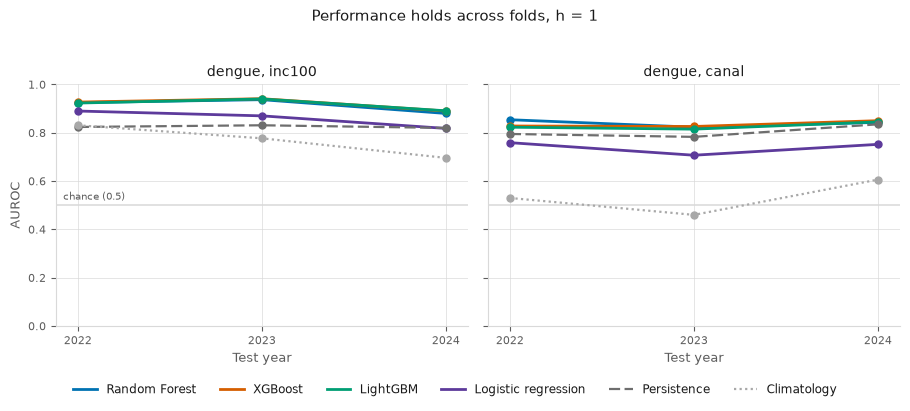

In [17]:
if stability:
    fig, axes = plt.subplots(1, len(stability), figsize=(4.6 * len(stability), 3.6),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (definition, tbl) in zip(axes, stability.items()):
        for model in PLOT_ORDER:
            label = MODEL_LABELS[model]
            if label not in tbl.index:
                continue
            ax.plot(TEST_YEARS, tbl.loc[label, TEST_YEARS].values,
                    marker="o", markersize=5, **model_line_kwargs(model))
        # Full 0-1 axis, like every other panel in this notebook, with the
        # chance level drawn: an AUROC of 0.5 is what a coin flip scores, so a
        # curve's distance above that line is the whole of what it is worth.
        ax.axhline(0.5, color=GRID, linewidth=1.1, zorder=1)
        ax.set_xticks(TEST_YEARS)
        ax.set_ylim(0, 1.0)
        ax.set_title(f"dengue, {definition}", fontsize=10, color=INK)
        style_axes(ax, xlabel="Test year")
        ax.set_xlim(TEST_YEARS[0] - 0.12, TEST_YEARS[-1] + 0.12)
    style_axes(axes[0], ylabel="AUROC")
    axes[0].annotate("chance (0.5)", (TEST_YEARS[0] - 0.08, 0.5), xytext=(0, 4),
                     textcoords="offset points", fontsize=7.5, color=MUTED)

    # Six series is past the point where direct labels stay legible — the tree
    # models sit within 0.01 of each other and their labels collide. One shared
    # legend instead, below both panels.
    handles = [Line2D([], [], label=MODEL_LABELS[m], **model_line_kwargs(m))
               for m in PLOT_ORDER]
    fig.legend(handles=handles, frameon=False, fontsize=8.5, labelcolor=INK,
               loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=6)
    fig.suptitle("Performance holds across folds, h = 1", fontsize=11, color=INK, y=1.03)
    fig.tight_layout()
    save_fig(fig, "stability_by_year")
    plt.show()


## Section 10 — The alert budget: what a surveillance team actually gets

AUROC answers a question nobody in a health department asks. The real constraint is
a budget: a state team can investigate some number of municipalities this month, not
645. So rank the municipalities by predicted probability *within each month* and take
the top k. Two numbers follow, and they are the ones worth arguing about:

- **Recall@k** — of the outbreaks that happened this month, how many were on the list.
- **Precision@k** — of the k municipalities given extra attention, how many were really in outbreak.

This is deliberately threshold-free. Choosing an operating threshold means fitting
one more number, and fitting it on the test years would reintroduce, through the back
door, exactly the leakage the rest of this pipeline was built to avoid. Ranking within
a month needs no such choice.
Two things to read carefully in the figure. The grey ceiling is what a perfect
ranking would catch — with roughly 163 outbreak municipalities in an average test
month, no ranking can catch 100% by supporting 50 of them, so the models should be read
against that curve and not against the top of the panel. And the three tree models
lie on top of each other almost exactly: that overlap is the result, not a plotting
error, and it is the same overlap the AUPRC column shows to the third decimal.

In [18]:
K_VALUES = [10, 25, 50, 100]

def alert_budget(frame, k_values=K_VALUES):
    """Rank municipalities within each month; score the top k."""
    out = []
    total_pos = int(frame["y_true"].sum())
    months = frame.groupby(["ano", "mes"], sort=True)
    for k in k_values:
        caught = alerts = 0
        for _, month in months:
            top = month.nlargest(k, "proba")
            caught += int(top["y_true"].sum())
            alerts += len(top)
        out.append({
            "k": k,
            "recall_%": 100 * caught / total_pos if total_pos else np.nan,
            "precision_%": 100 * caught / alerts if alerts else np.nan,
            "outbreaks_caught": caught,
            "supported": alerts,
        })
    return pd.DataFrame(out).set_index("k"), total_pos

budget_path = PRED_DIR / f"{DISEASE}_{DEFINITION}_h{HORIZON}.parquet"
budget_tables = {}
if budget_path.exists():
    bp = pd.read_parquet(budget_path)
    n_months = bp.groupby(["ano", "mes"]).ngroups
    print(f"Alert budget: {DISEASE}/{DEFINITION}/h{HORIZON}, "
          f"{n_months} test months, {bp['cod_ibge'].nunique()} municipalities/month")
    for model in PLOT_ORDER:
        sub = bp[bp["model"] == model]
        if sub.empty:
            continue
        tbl, total_pos = alert_budget(sub)
        budget_tables[model] = tbl
    print(f"Outbreak months in the test set: {total_pos:,}\n")

    show = pd.concat({MODEL_LABELS[m]: t[["recall_%", "precision_%"]]
                      for m, t in budget_tables.items()}, names=["model"])
    print(show.round(1).to_string())
    show.to_csv(TABLES_DIR / "table_alert_budget.csv")
    print(f"\n  Saved: tables/table_alert_budget.csv")

    rf_budget = budget_tables.get("rf")
    if rf_budget is not None:
        for k in K_VALUES:
            r = rf_budget.loc[k]
            print(f"  Support the top {k:>3} municipalities/month: catch {r['recall_%']:.0f}% "
                  f"of outbreaks, {r['precision_%']:.0f}% of them really in outbreak")


Alert budget: dengue/inc100/h1, 36 test months, 645 municipalities/month


Outbreak months in the test set: 5,883

                         recall_%  precision_%
model               k                         
Random Forest       10        4.3         70.8
                    25       10.1         66.3
                    50       19.2         62.7
                    100      34.5         56.4
XGBoost             10        4.3         70.0
                    25       10.5         68.3
                    50       19.4         63.3
                    100      34.6         56.6
LightGBM            10        4.4         71.9
                    25       10.5         68.6
                    50       19.6         64.2
                    100      34.8         56.9
Logistic regression 10        3.7         59.7
                    25        8.3         54.4
                    50       15.7         51.4
                    100      28.7         47.0
Persistence         10        4.1         67.8
                    25        9.8         64.2
                    

  Saved: figuras/alert_budget.pdf and .png


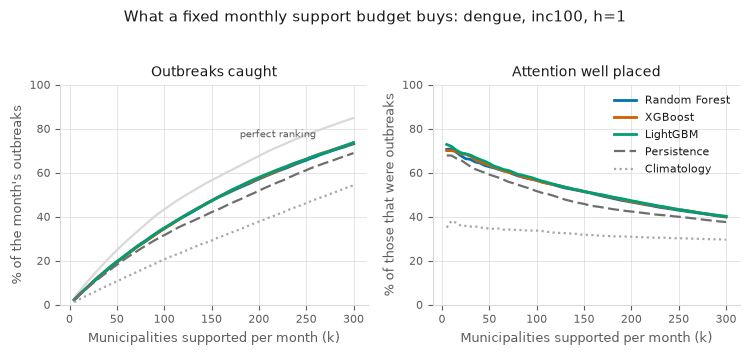

In [19]:
# The full curve, not just four points: recall and precision as the budget grows.
if budget_path.exists():
    fine_k = list(range(5, 301, 5))
    curves = {}
    for model in ("rf", "xgb", "lgbm", "persistence", "climatology"):
        sub = bp[bp["model"] == model]
        if sub.empty:
            continue
        curves[model], _ = alert_budget(sub, fine_k)

    # The ceiling: a perfect ranking puts the outbreak municipalities first.
    # Without it, "35% at k=100" reads as failure rather than as most of what
    # any ranking could achieve on a month with ~163 outbreaks in 645 places.
    rf_months = list(bp[bp["model"] == "rf"].groupby(["ano", "mes"]))
    total_pos_rf = int(bp[bp["model"] == "rf"]["y_true"].sum())
    oracle = [100 * sum(min(k, int(m["y_true"].sum())) for _, m in rf_months)
              / total_pos_rf for k in fine_k]

    fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.4))
    axes[0].plot(fine_k, oracle, color=GRID, linewidth=1.6, zorder=1)
    anchor = int(len(fine_k) * 0.72)   # above the grey line, clear of the models
    axes[0].annotate("perfect ranking", (fine_k[anchor], oracle[anchor]),
                     xytext=(0, 7), textcoords="offset points", fontsize=7.5,
                     color=MUTED, ha="center")
    for model, curve in curves.items():
        for ax, col in zip(axes, ("recall_%", "precision_%")):
            ax.plot(curve.index, curve[col], **model_line_kwargs(model))
    for ax, (col, title) in zip(axes, [
            ("recall_%", "Outbreaks caught"), ("precision_%", "Attention well placed")]):
        ax.set_title(title, fontsize=10, color=INK)
        style_axes(ax, xlabel="Municipalities supported per month (k)")
        ax.set_ylim(0, 100)
    style_axes(axes[0], ylabel="% of the month's outbreaks")
    style_axes(axes[1], ylabel="% of those that were outbreaks")

    handles = [Line2D([], [], label=MODEL_LABELS[m], **model_line_kwargs(m))
               for m in curves]
    axes[1].legend(handles=handles, frameon=False, fontsize=8, labelcolor=INK,
                   loc="upper right")
    fig.suptitle(f"What a fixed monthly support budget buys: {DISEASE}, "
                 f"{DEFINITION}, h={HORIZON}", fontsize=11, color=INK, y=1.03)
    fig.tight_layout()
    save_fig(fig, "alert_budget")
    plt.show()


## Section 11 — Calibration

Ranking is not the same as being right about magnitude. A model can order
municipalities perfectly and still say "80%" for events that happen half the time.
Anyone who plans on the number rather than the ranking needs the number to mean
something, so: the Brier score, and the reliability curve behind it.

The diagonal is perfect calibration. Below it the model is overconfident, above it
too cautious. Persistence sits at the two corners by construction — it only ever
predicts 0 or 1 — which is why its Brier score is readable but its curve is not.


In [20]:
def brier(frame):
    return float(((frame["proba"] - frame["y_true"]) ** 2).mean())

def reliability(frame, bins=10):
    """Observed frequency against predicted probability, in equal-width bins."""
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(frame["proba"], edges) - 1, 0, bins - 1)
    out = []
    for b in range(bins):
        sel = idx == b
        if sel.sum() == 0:
            continue
        out.append({"predicted": frame.loc[sel, "proba"].mean(),
                    "observed": frame.loc[sel, "y_true"].mean(),
                    "n": int(sel.sum())})
    return pd.DataFrame(out)

if budget_path.exists():
    brier_rows = []
    base_rate = bp["y_true"].mean()
    # A model that always predicts the base rate: the reference every Brier
    # score has to beat before it means anything.
    reference = float(((base_rate - bp[bp["model"] == "rf"]["y_true"]) ** 2).mean())
    for model in PLOT_ORDER:
        sub = bp[bp["model"] == model]
        if sub.empty:
            continue
        b = brier(sub)
        brier_rows.append({"model": MODEL_LABELS[model], "brier": b,
                           "skill_vs_base_rate_%": 100 * (1 - b / reference)})
    brier_table = pd.DataFrame(brier_rows).set_index("model")
    print(f"Calibration: {DISEASE}/{DEFINITION}/h{HORIZON}")
    print(f"  Test base rate: {base_rate:.3f}   "
          f"Brier of always predicting it: {reference:.4f}\n")
    print(brier_table.round({"brier": 4, "skill_vs_base_rate_%": 1}).to_string())
    brier_table.to_csv(TABLES_DIR / "table_calibration.csv")
    print(f"\n  Saved: tables/table_calibration.csv")


Calibration: dengue/inc100/h1
  Test base rate: 0.253   Brier of always predicting it: 0.1892

                      brier  skill_vs_base_rate_%
model                                            
Random Forest        0.1066                  43.7
XGBoost              0.1005                  46.9
LightGBM             0.0973                  48.6
Logistic regression  0.1572                  16.9
Persistence          0.1256                  33.6
Climatology          0.1763                   6.8

  Saved: tables/table_calibration.csv


  Saved: figuras/calibration.pdf and .png


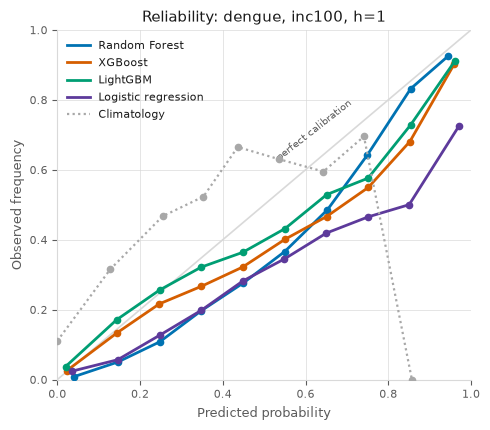

In [21]:
if budget_path.exists():
    fig, ax = plt.subplots(figsize=(5.0, 4.4))
    ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.2, zorder=1)
    ax.annotate("perfect calibration", (0.62, 0.62), rotation=38, fontsize=7.5,
                color=MUTED, ha="center", va="bottom")
    for model in ("rf", "xgb", "lgbm", "logreg", "climatology"):
        sub = bp[bp["model"] == model]
        if sub.empty:
            continue
        curve = reliability(sub)
        ax.plot(curve["predicted"], curve["observed"], marker="o", markersize=4.5,
                zorder=3, **model_line_kwargs(model))
    style_axes(ax, xlabel="Predicted probability", ylabel="Observed frequency")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    handles = [Line2D([], [], label=MODEL_LABELS[m], **model_line_kwargs(m))
               for m in ("rf", "xgb", "lgbm", "logreg", "climatology")]
    ax.legend(handles=handles, frameon=False, fontsize=8, labelcolor=INK,
              loc="upper left")
    ax.set_title(f"Reliability: {DISEASE}, {DEFINITION}, h={HORIZON}",
                 fontsize=11, color=INK)
    fig.tight_layout()
    save_fig(fig, "calibration")
    plt.show()


## Section 12 — ROC and precision–recall curves

The two summary numbers of Section 1 are areas under these curves. Printing the
curves themselves shows *where* the area comes from, which the scalar cannot: two
models with the same AUPRC can be useful in completely different operating regions.

The precision–recall panel carries a horizontal line at the base rate. That is what
a coin-flip model scores, and it is the only honest floor for AUPRC — the ROC panel's
diagonal is the equivalent, and it is why AUROC looks flattering for rare events
while AUPRC does not.


  Saved: figuras/roc_pr_curves.pdf and .png


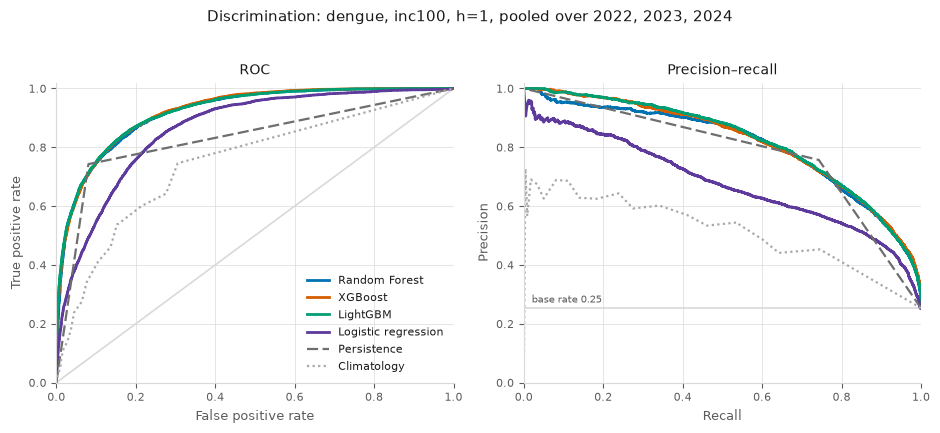

In [22]:
from sklearn.metrics import roc_curve, precision_recall_curve

if budget_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
    base = bp["y_true"].mean()

    axes[0].plot([0, 1], [0, 1], color=GRID, linewidth=1.2)
    axes[1].axhline(base, color=GRID, linewidth=1.2)
    axes[1].annotate(f"base rate {base:.2f}", (0.02, base), xytext=(0, 4),
                     textcoords="offset points", fontsize=7.5, color=MUTED)

    for model in PLOT_ORDER:
        sub = bp[bp["model"] == model]
        if sub.empty or sub["y_true"].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(sub["y_true"], sub["proba"])
        axes[0].plot(fpr, tpr, **model_line_kwargs(model))
        prec, rec, _ = precision_recall_curve(sub["y_true"], sub["proba"])
        axes[1].plot(rec, prec, **model_line_kwargs(model))

    axes[0].set_title("ROC", fontsize=10, color=INK)
    style_axes(axes[0], xlabel="False positive rate", ylabel="True positive rate")
    axes[1].set_title("Precision–recall", fontsize=10, color=INK)
    style_axes(axes[1], xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

    handles = [Line2D([], [], label=MODEL_LABELS[m], **model_line_kwargs(m))
               for m in PLOT_ORDER if (bp["model"] == m).any()]
    axes[0].legend(handles=handles, frameon=False, fontsize=8, labelcolor=INK,
                   loc="lower right")
    fig.suptitle(f"Discrimination: {DISEASE}, {DEFINITION}, h={HORIZON}, "
                 f"pooled over {', '.join(str(y) for y in TEST_YEARS)}",
                 fontsize=11, color=INK, y=1.02)
    fig.tight_layout()
    save_fig(fig, "roc_pr_curves")
    plt.show()


## Section 13 — Where the model works and where it does not

An average over 645 municipalities and 36 months is a claim about no municipality in
particular. Two cuts break it open.

**By calendar month of the target.** Dengue in São Paulo is seasonal, so a model can
score well by learning the season and nothing else. If performance is flat across the
year, the model is doing more than reciting the calendar.

**By municipality size.** Small municipalities have noisy incidence — a handful of
cases crosses a per-100k threshold — and the count-based definitions inherit that
noise. If performance collapses in the smallest stratum, the headline number is
carried by the large cities where surveillance is already strongest, which would be
the least useful place to be right.


In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

def safe_auc(y, p):
    return roc_auc_score(y, p) if pd.Series(y).nunique() > 1 else np.nan

if budget_path.exists():
    # The month being predicted is h months after the row's own month.
    total = bp["ano"] * 12 + (bp["mes"] - 1) + HORIZON
    bp["target_mes"] = (total % 12) + 1

    rf_only = bp[bp["model"] == "rf"]

    # Per month AND per fold, then aggregated: the line is the mean over the three
    # test years and auroc_min/auroc_max are the range between them.
    per_fold = (rf_only.groupby(["target_mes", "test_year"])
                .apply(lambda g: pd.Series({
                    "auroc": safe_auc(g["y_true"], g["proba"]),
                    "auprc": average_precision_score(g["y_true"], g["proba"])
                             if g["y_true"].nunique() > 1 else np.nan,
                    "base_rate": g["y_true"].mean(),
                    "n": len(g)}), include_groups=False))
    season = per_fold.groupby(level="target_mes").agg(
        auroc=("auroc", "mean"), auroc_min=("auroc", "min"), auroc_max=("auroc", "max"),
        auprc=("auprc", "mean"), base_rate=("base_rate", "mean"), n=("n", "sum"))
    MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    season.index = [MONTHS[m - 1] for m in season.index]
    print(f"Random Forest by calendar month of the target: {DISEASE}/{DEFINITION}/h{HORIZON}")
    print(season.round(3).to_string())
    season.to_csv(TABLES_DIR / "table_by_season.csv")
    print(f"\n  AUROC range across months: "
          f"{season['auroc'].min():.3f} to {season['auroc'].max():.3f}")
    print(f"  Saved: tables/table_by_season.csv")


Random Forest by calendar month of the target: dengue/inc100/h1
     auroc  auroc_min  auroc_max  auprc  base_rate       n
Jan  0.880      0.753      0.956  0.653      0.132  1935.0
Feb  0.806      0.602      0.928  0.744      0.304  1935.0
Mar  0.826      0.722      0.881  0.853      0.490  1935.0
Apr  0.834      0.725      0.890  0.898      0.608  1935.0
May  0.853      0.745      0.917  0.907      0.616  1935.0
Jun  0.847      0.774      0.887  0.732      0.398  1935.0
Jul  0.873      0.845      0.920  0.443      0.163  1935.0
Aug  0.893      0.866      0.922  0.355      0.075  1935.0
Sep  0.896      0.866      0.937  0.215      0.035  1935.0
Oct  0.872      0.838      0.896  0.252      0.045  1935.0
Nov  0.901      0.890      0.911  0.350      0.064  1935.0
Dec  0.879      0.826      0.907  0.510      0.111  1935.0

  AUROC range across months: 0.806 to 0.901
  Saved: tables/table_by_season.csv


In [24]:
if budget_path.exists():
    pop = (master[["cod_ibge", "ano", "mes", "pop_residente"]]
           .rename(columns={"pop_residente": "pop"}))
    sized = bp.merge(pop, on=["cod_ibge", "ano", "mes"], how="left", validate="m:1")
    print(f"Rows without population: {sized['pop'].isna().sum():,}")

    # Fixed cut-points, not quantiles: they are the sizes a health department
    # already thinks in, and they stay comparable if the cohort changes.
    EDGES = [0, 10_000, 50_000, 200_000, np.inf]
    NAMES = ["< 10k", "10k–50k", "50k–200k", "> 200k"]
    sized["stratum"] = pd.cut(sized["pop"], EDGES, labels=NAMES, right=False)

    rows = []
    for model in ("rf", "persistence"):
        sub = sized[sized["model"] == model]
        for name in NAMES:
            g = sub[sub["stratum"] == name]
            if g.empty:
                continue
            rows.append({
                "model": MODEL_LABELS[model], "stratum": name,
                "municipalities": g["cod_ibge"].nunique(),
                "base_rate_%": 100 * g["y_true"].mean(),
                "auroc": safe_auc(g["y_true"], g["proba"]),
                "auprc": average_precision_score(g["y_true"], g["proba"])
                         if g["y_true"].nunique() > 1 else np.nan,
            })
    size_table = pd.DataFrame(rows).set_index(["model", "stratum"])
    size_table["lift"] = size_table["auprc"] / (size_table["base_rate_%"] / 100)
    print(f"\nBy municipality size: {DISEASE}/{DEFINITION}/h{HORIZON}")
    print(size_table.round(3).to_string())
    size_table.to_csv(TABLES_DIR / "table_by_municipality_size.csv")
    print(f"\n  Saved: tables/table_by_municipality_size.csv")


Rows without population: 0

By municipality size: dengue/inc100/h1
                        municipalities  base_rate_%  auroc  auprc   lift
model         stratum                                                   
Random Forest < 10k                275       26.774  0.890  0.765  2.858
              10k–50k              249       24.746  0.925  0.819  3.309
              50k–200k             105       24.113  0.955  0.896  3.716
              > 200k                42       22.105  0.960  0.891  4.029
Persistence   < 10k                275       26.774  0.817  0.611  2.283
              10k–50k              249       24.746  0.837  0.634  2.564
              50k–200k             105       24.113  0.849  0.657  2.724
              > 200k                42       22.105  0.854  0.650  2.942

  Saved: tables/table_by_municipality_size.csv


  Saved: figuras/season_and_size.pdf and .png


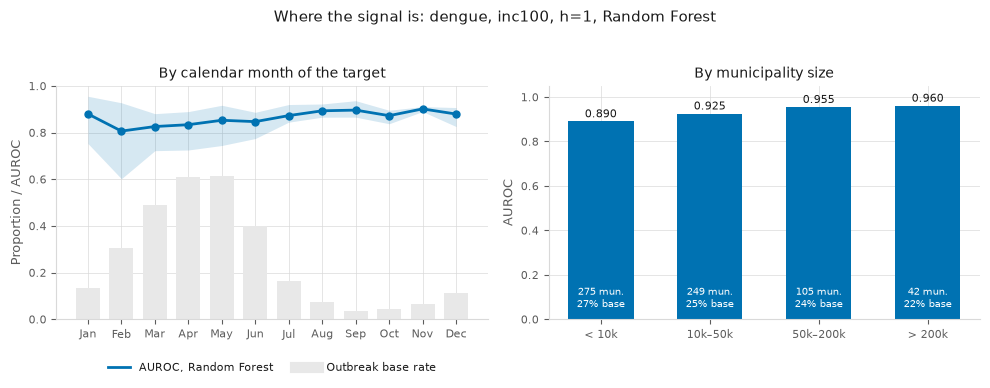

In [25]:
if budget_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))

    # Left: season. Bars are the base rate, the line is AUROC — two different
    # quantities on one panel, so the bars are deliberately pale and unlabelled
    # on their own axis; the line carries the reading.
    ax = axes[0]
    ax.bar(range(len(season)), season["base_rate"], color="#e8e8e8",
           width=0.72, zorder=1, label="Outbreak base rate")
    ax.fill_between(range(len(season)), season["auroc_min"], season["auroc_max"],
                    color=MODEL_COLORS["rf"], alpha=0.16, lw=0, zorder=2)
    ax.plot(range(len(season)), season["auroc"], marker="o", markersize=5,
            zorder=3, **model_line_kwargs("rf"))
    ax.set_xticks(range(len(season)))
    ax.set_xticklabels(season.index, fontsize=8)
    ax.set_ylim(0, 1)
    style_axes(ax, ylabel="Proportion / AUROC")
    ax.set_title("By calendar month of the target", fontsize=10, color=INK)
    ax.legend(handles=[
        Line2D([], [], label="AUROC, Random Forest", **model_line_kwargs("rf")),
        Line2D([], [], color="#e8e8e8", linewidth=8, label="Outbreak base rate")],
        frameon=False, fontsize=8, labelcolor=INK, loc="upper center",
        bbox_to_anchor=(0.5, -0.14), ncol=2)

    # Right: size strata, Random Forest only.
    ax = axes[1]
    rf_sizes = size_table.loc[MODEL_LABELS["rf"]]
    xs = range(len(rf_sizes))
    ax.bar(xs, rf_sizes["auroc"], color=MODEL_COLORS["rf"], width=0.6, zorder=2)
    for x, (name, row) in zip(xs, rf_sizes.iterrows()):
        ax.annotate(f"{row['auroc']:.3f}", (x, row["auroc"]), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
        # White, and short enough to stay inside the bar: text that overflows
        # a bar this colour lands white-on-white and disappears.
        ax.annotate(f"{int(row['municipalities'])} mun.\n{row['base_rate_%']:.0f}% base",
                    (x, 0.04), ha="center", fontsize=7, color="#ffffff", va="bottom")
    ax.set_xticks(list(xs))
    ax.set_xticklabels(rf_sizes.index, fontsize=8)
    ax.set_ylim(0, 1.05)
    style_axes(ax, ylabel="AUROC")
    ax.set_title("By municipality size", fontsize=10, color=INK)

    fig.suptitle(f"Where the signal is: {DISEASE}, {DEFINITION}, h={HORIZON}, "
                 f"Random Forest", fontsize=11, color=INK, y=1.03)
    fig.tight_layout()
    save_fig(fig, "season_and_size")
    plt.show()


## Section 14 — Every evaluable combination, at every horizon

The full grid, for the appendix: each disease and definition that Section 7 marked
evaluable, scored at all six horizons. This is the table that lets a reader check any
claim made elsewhere in the paper without rerunning anything.

Lift is the column to read for the rare diseases. Chikungunya and zika have outbreak
rates near 1%, so an AUPRC of 0.32 is not a weak result — it is roughly 26 times what
guessing achieves. Reporting AUPRC alone would make the rare diseases look like
failures and the common one look easy, which is backwards.
The `folds` column is there because prevalence in this table is not the prevalence in
Section 7. Here it is measured over the folds each combo could actually be *scored*
on, which is the right reference for its AUPRC; a fold with no positive month is
dropped, because AUPRC is undefined on it. Section 7 divides by all three test years
regardless. Chikungunya/inc100 is where the two diverge most — 0.46% over two scorable
folds against 0.31% over all three — so any figure quoted from this table should say
which denominator it used.

In [26]:
def best_of(rows, metric="auprc"):
    rows = rows.dropna(subset=[metric])
    if rows.empty:
        return np.nan, np.nan
    mean = rows.groupby("model")[metric].mean()
    return MODEL_LABELS.get(mean.idxmax(), mean.idxmax()), mean.max()

grid_rows = []
for disease in DISEASES:
    for definition in DEFINITIONS:
        if evaluability.loc[(disease, definition), "verdict"] != "evaluable":
            continue
        for h in range(1, 7):
            rows = combo_rows(disease, definition, h).dropna(subset=["auroc"])
            if rows.empty:
                continue
            prev = prevalence_of(rows)
            rf = rows[rows["model"] == "rf"]
            best_model, best_auprc = best_of(rows)
            grid_rows.append({
                "disease": disease, "definition": definition, "h": h,
                "prevalence_%": 100 * prev,
                "rf_auroc": rf["auroc"].mean(),
                "rf_auroc_min": rf["auroc"].min(), "rf_auroc_max": rf["auroc"].max(),
                "rf_auprc": rf["auprc"].mean(),
                "rf_lift": rf["auprc"].mean() / prev if prev else np.nan,
                "folds": int(rows["test_year"].nunique()),
                "best_model": best_model, "best_auprc": best_auprc,
            })

full_grid = pd.DataFrame(grid_rows).set_index(["disease", "definition", "h"])
print("Every evaluable combination")
print(full_grid.round(3).to_string())
full_grid.to_csv(TABLES_DIR / "table_full_grid.csv")
print(f"\n  {len(full_grid)} rows across "
      f"{full_grid.index.droplevel('h').nunique()} disease x definition pairs")
print(f"  Saved: tables/table_full_grid.csv")

winners = full_grid["best_model"].value_counts()
print("\nBest model by AUPRC, counted over those rows:")
for model, n in winners.items():
    print(f"  {model:<20} {n:>2}")


Every evaluable combination
                          prevalence_%  rf_auroc  rf_auroc_min  rf_auroc_max  rf_auprc  rf_lift  folds     best_model  best_auprc
disease     definition h                                                                                                         
dengue      inc100     1        25.336     0.914         0.880         0.937     0.806    3.180      3       LightGBM       0.817
                       2        25.336     0.878         0.826         0.912     0.711    2.806      3        XGBoost       0.724
                       3        25.336     0.856         0.788         0.894     0.645    2.547      3        XGBoost       0.673
                       4        25.336     0.843         0.766         0.883     0.609    2.404      3        XGBoost       0.647
                       5        25.336     0.825         0.732         0.875     0.572    2.257      3        XGBoost       0.599
                       6        25.336     0.812         0.717

  Saved: figuras/horizon_by_disease.pdf and .png


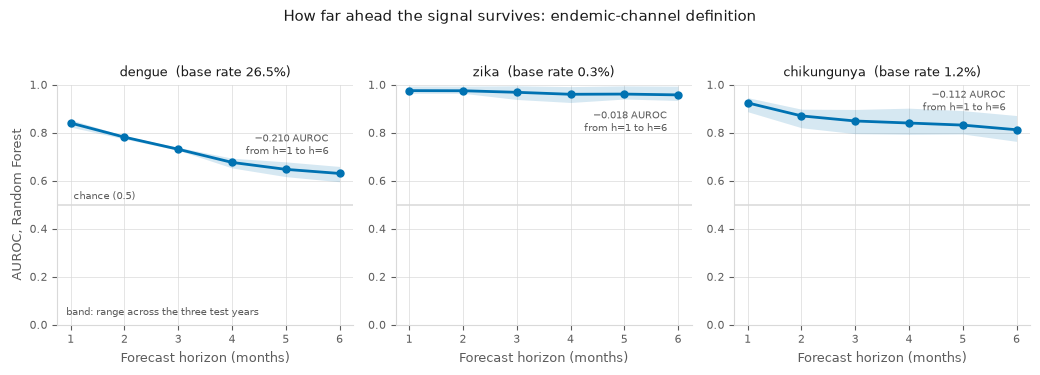

In [27]:
# Horizon decay is the paper's argument for how far ahead this is usable.
# One panel per disease so the very different base rates never share a scale.
decay = full_grid.reset_index()
decay = decay[decay["definition"] == "canal"]
present = [d for d in DISEASES if d in set(decay["disease"])]

if present:
    fig, axes = plt.subplots(1, len(present), figsize=(3.5 * len(present), 3.6))
    axes = np.atleast_1d(axes)
    for ax, disease in zip(axes, present):
        sub = decay[decay["disease"] == disease].sort_values("h")
        ax.fill_between(sub["h"], sub["rf_auroc_min"], sub["rf_auroc_max"],
                        color=MODEL_COLORS["rf"], alpha=0.16, lw=0)
        ax.plot(sub["h"], sub["rf_auroc"], marker="o", markersize=5,
                **model_line_kwargs("rf"))
        drop = sub["rf_auroc"].iloc[0] - sub["rf_auroc"].iloc[-1]
        # A flat, high curve leaves no room above it: drop the note below instead
        # of letting it run into the panel title.
        high = sub["rf_auroc"].iloc[-1] > 0.93
        ax.annotate(f"−{drop:.3f} AUROC\nfrom h=1 to h=6",
                    (sub["h"].iloc[-1], sub["rf_auroc"].iloc[-1]),
                    xytext=(-8, -26 if high else 14), textcoords="offset points",
                    fontsize=7.5, color=MUTED, ha="right")
        ax.set_title(f"{disease}  (base rate {sub['prevalence_%'].iloc[0]:.1f}%)",
                     fontsize=9.5, color=INK)
        # Full 0-1 axis, like every other panel in this notebook, with the
        # chance level drawn: an AUROC of 0.5 is what a coin flip scores, so a
        # curve's distance above that line is the whole of what it is worth.
        ax.axhline(0.5, color=GRID, linewidth=1.1, zorder=1)
        ax.set_xticks(range(1, 7))
        ax.set_ylim(0, 1.0)
        style_axes(ax, xlabel="Forecast horizon (months)")
    style_axes(axes[0], ylabel="AUROC, Random Forest")
    axes[0].annotate("chance (0.5)", (1, 0.5), xytext=(2, 4),
                     textcoords="offset points", fontsize=7.5, color=MUTED)
    axes[0].annotate("band: range across the three test years", (0.03, 0.04),
                     xycoords="axes fraction", fontsize=7.5, color=MUTED)
    fig.suptitle("How far ahead the signal survives: endemic-channel definition",
                 fontsize=11, color=INK, y=1.03)
    fig.tight_layout()
    save_fig(fig, "horizon_by_disease")
    plt.show()


  Saved: figuras/onset_vs_continuation.pdf and .png


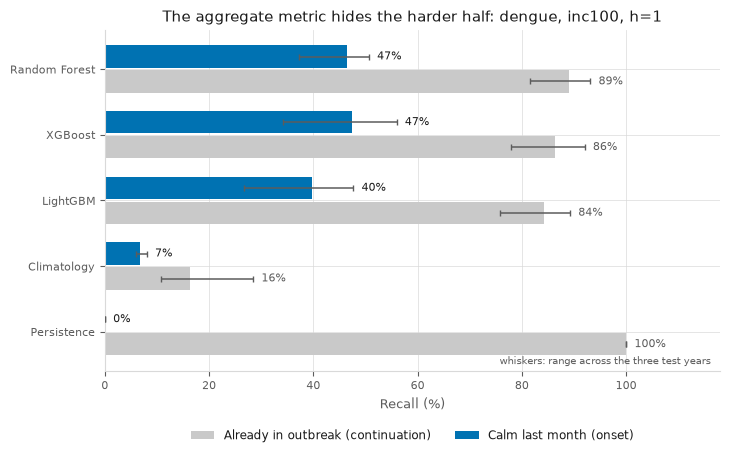

In [28]:
# The onset/continuation split, as a figure: the paper's central claim.
if onset_table is not None:
    order = [m for m in ("Random Forest", "XGBoost", "LightGBM",
                         "Climatology", "Persistence") if m in onset_table.index]
    ot = onset_table.loc[order]
    y = np.arange(len(ot))

    # The same split, recomputed inside each test year, so the bars can carry the
    # range instead of implying the single number is all there is.
    spread = {}
    for model in ("rf", "xgb", "lgbm", "climatology", "persistence"):
        label = MODEL_LABELS[model]
        if label not in ot.index:
            continue
        rows_ = [phase_metrics(fold) for _, fold in
                 preds[preds["model"] == model].groupby("test_year")]
        for key in ("recall_onset", "recall_continuation"):
            vals = [r[key] for r in rows_ if not pd.isna(r[key])]
            spread[(label, key)] = (min(vals), max(vals)) if vals else (np.nan, np.nan)

    def err(label, key, mean):
        lo, hi = spread.get((label, key), (np.nan, np.nan))
        if pd.isna(lo):
            return [[0.0], [0.0]]
        return [[100 * mean - 100 * lo], [100 * hi - 100 * mean]]
    fig, ax = plt.subplots(figsize=(7.4, 0.62 * len(ot) + 1.6))
    ax.barh(y + 0.19, 100 * ot["recall_continuation"], height=0.34,
            color="#c9c9c9", zorder=2, label="Already in outbreak (continuation)")
    ax.barh(y - 0.19, 100 * ot["recall_onset"], height=0.34,
            color=MODEL_COLORS["rf"], zorder=2, label="Calm last month (onset)")
    # Whiskers span the lowest to the highest of the three test years.
    for yi, (label, row) in zip(y, ot.iterrows()):
        for offset, key in ((0.19, "recall_continuation"), (-0.19, "recall_onset")):
            ax.errorbar(100 * row[key], yi + offset,
                        xerr=err(label, key, row[key]), fmt="none",
                        ecolor=MUTED, elinewidth=1.1, capsize=2.5, zorder=4)
    def whisker_end(label, key, mean):
        """Right edge of the whisker, so the number never lands on the cap."""
        hi = spread.get((label, key), (np.nan, np.nan))[1]
        return 100 * (mean if pd.isna(hi) else max(mean, hi))

    for yi, (label, row) in zip(y, ot.iterrows()):
        ax.annotate(f"{100 * row['recall_continuation']:.0f}%",
                    (whisker_end(label, "recall_continuation",
                                 row["recall_continuation"]), yi + 0.19),
                    xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=8, color=MUTED)
        ax.annotate(f"{100 * row['recall_onset']:.0f}%",
                    (whisker_end(label, "recall_onset", row["recall_onset"]),
                     yi - 0.19), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK)
    ax.set_yticks(y)
    ax.set_yticklabels(ot.index, fontsize=9, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, 118)
    style_axes(ax, xlabel="Recall (%)")
    ax.legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper center",
              bbox_to_anchor=(0.5, -0.14), ncol=2)
    ax.set_title(f"The aggregate metric hides the harder half: {DISEASE}, "
                 f"{DEFINITION}, h={HORIZON}", fontsize=11, color=INK)
    ax.annotate("whiskers: range across the three test years", (0.985, 0.02),
                xycoords="axes fraction", ha="right", fontsize=7.5, color=MUTED)
    fig.tight_layout()
    save_fig(fig, "onset_vs_continuation")
    plt.show()


  Saved: figuras/kappa_heatmap.pdf and .png


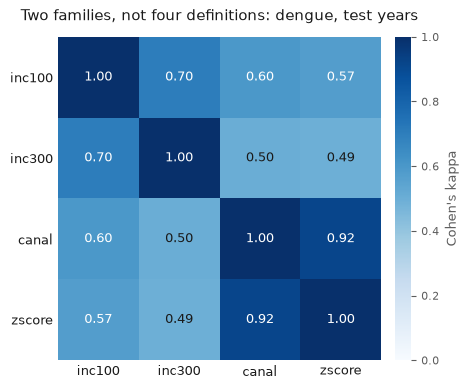

In [29]:
# Kappa as a heatmap: the two families separate at a glance.
fig, ax = plt.subplots(figsize=(4.6, 4.0))
mat = kappa.astype(float).values
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(DEFINITIONS)), DEFINITIONS, fontsize=9, color=INK)
ax.set_yticks(range(len(DEFINITIONS)), DEFINITIONS, fontsize=9, color=INK)
for i in range(len(DEFINITIONS)):
    for j in range(len(DEFINITIONS)):
        v = mat[i, j]
        ax.annotate(f"{v:.2f}", (j, i), ha="center", va="center", fontsize=9,
                    color="#ffffff" if v > 0.55 else INK)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("Cohen's kappa", fontsize=9, color=MUTED)
cb.ax.tick_params(colors=MUTED, labelsize=8)
cb.outline.set_visible(False)
ax.set_title("Two families, not four definitions: dengue, test years",
             fontsize=10.5, color=INK, pad=12)
fig.tight_layout()
save_fig(fig, "kappa_heatmap")
plt.show()


## Section 15 — Threshold curves for both definitions

Section 3 swept the decision threshold for one definition. The same sweep across
both — incidence and endemic channel, all months and onsets only — is what shows
that the trade-off is a property of the task rather than of one labelling choice.

Onsets are the restriction that matters: a municipality calm in month *t* that
enters outbreak in *t+h*. Keeping an alert up on an outbreak already under way is
free, so any precision measured over all months is inflated by exactly the cases a
health department did not need a model for.


  Saved: figuras/global_threshold.pdf and .png


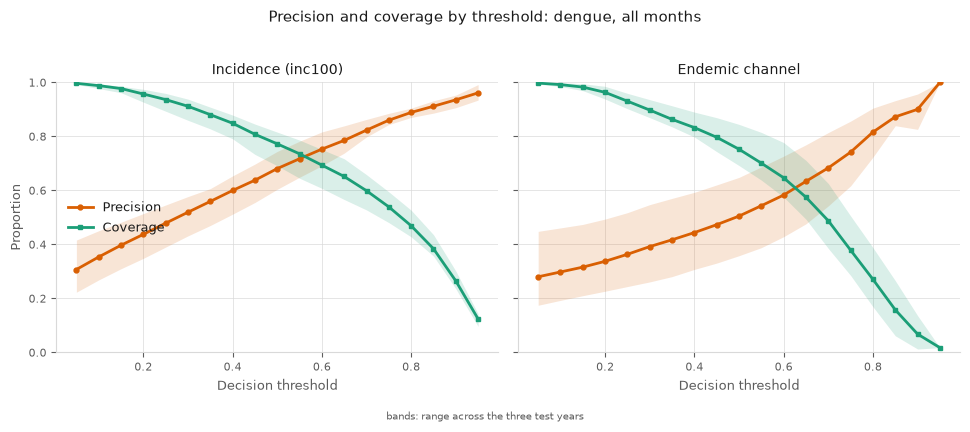

  Saved: figuras/onset_threshold.pdf and .png


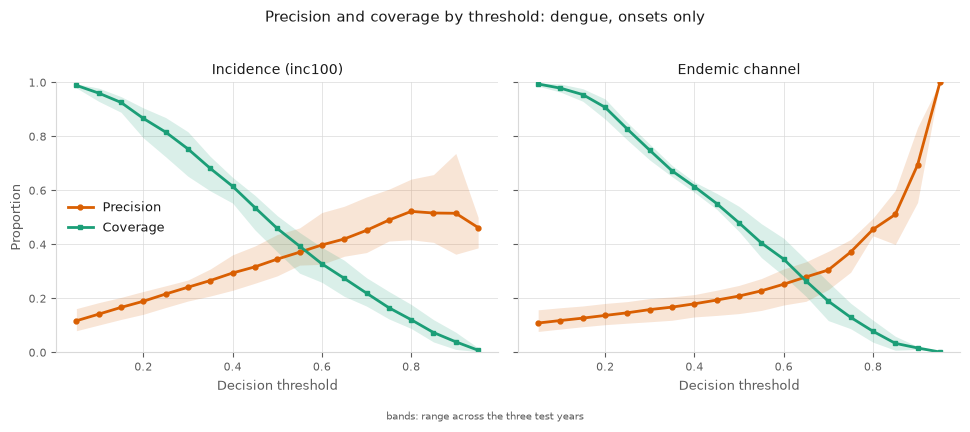

In [30]:
SWEEP_DEFS = [("inc100", "Incidence (inc100)"), ("canal", "Endemic channel")]
GRID_TH = np.arange(0.05, 0.96, 0.05)

def curves_for(definition, onsets_only):
    """Threshold sweep for one definition, reusing Section 3's per-fold sweep."""
    path = PRED_DIR / f"{DISEASE}_{definition}_h{HORIZON}.parquet"
    if not path.exists():
        return None
    frame = pd.read_parquet(path)
    frame = frame[frame["model"] == "rf"]
    label_col = f"{DISEASE}_{definition}"
    state = (labels[["cod_ibge", "ano", "mes", label_col]]
             .rename(columns={label_col: "surto_atual"}))
    frame = frame.merge(state, on=["cod_ibge", "ano", "mes"], how="left",
                        validate="m:1").dropna(subset=["surto_atual"])
    return sweep(frame, GRID_TH, restrict_to_calm=onsets_only)

def draw_threshold_figure(onsets_only, name, title):
    panels = [(lbl, curves_for(d, onsets_only)) for d, lbl in SWEEP_DEFS]
    panels = [(lbl, c) for lbl, c in panels if c is not None and not c.empty]
    if not panels:
        print(f"  {name}: no predictions on disk for either definition")
        return
    fig, axes = plt.subplots(1, len(panels), figsize=(4.9 * len(panels), 3.9),
                             sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (lbl, c) in zip(axes, panels):
        ax.fill_between(c["threshold"], c["precision_min"], c["precision_max"],
                        color=C_PRECISION, alpha=0.16, lw=0)
        ax.fill_between(c["threshold"], c["coverage_min"], c["coverage_max"],
                        color=C_COVERAGE, alpha=0.16, lw=0)
        ax.plot(c["threshold"], c["precision"], color=C_PRECISION, linewidth=2,
                marker="o", markersize=3.5, label="Precision")
        ax.plot(c["threshold"], c["coverage"], color=C_COVERAGE, linewidth=2,
                marker="s", markersize=3.5, label="Coverage")
        ax.set_title(lbl, fontsize=10, color=INK)
        ax.set_ylim(0, 1)
        style_axes(ax, xlabel="Decision threshold")
    style_axes(axes[0], ylabel="Proportion")
    axes[0].legend(frameon=False, fontsize=9, labelcolor=INK, loc="center left")
    fig.suptitle(title, fontsize=11, color=INK, y=1.02)
    fig.text(0.5, -0.03, "bands: range across the three test years", ha="center",
             fontsize=7.5, color=MUTED)
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()

draw_threshold_figure(False, "global_threshold",
                      f"Precision and coverage by threshold: {DISEASE}, all months")
draw_threshold_figure(True, "onset_threshold",
                      f"Precision and coverage by threshold: {DISEASE}, onsets only")


## Section 16 — What each family of variables is worth

Three complementary readings of the same question, because no single one settles it.

**Ablation** removes one group at a time and refits. A drop in AUPRC means the group
carried signal nothing else replaced. It is the strictest test, and it is silent
about groups that are merely redundant.

**Incremental value** starts from the obvious epidemiological baseline — the target
disease's own history, climate, seasonality — and adds one group at a time. It asks
the question a reviewer asks: given the predictors anyone would have used, does this
one add anything?

**SHAP** attributes each prediction to features and sums the attribution by group. It
credits redundant variables that the other two hide, and it says nothing about
whether the model would be worse without them.

Everything below refits the Random Forest with the exact configuration `03` uses, on
the exact features `03` builds. Rather than restate that code and let the two drift
apart, the next cell executes `03`'s own cells. The check is that the full-feature
baseline reproduces the AUROC and AUPRC already in `results/` — if it does not, the
two notebooks have diverged and nothing below can be trusted.


In [31]:
import json
import warnings

# Run 03's setup, feature, target and fold cells verbatim — same code, not a copy.
NB03 = PROJECT_ROOT / "notebooks" / "03_train.ipynb"
FEATURE_CELLS = [2, 4, 5, 7, 9]

_nb03 = json.loads(NB03.read_text())
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _i in FEATURE_CELLS:
        exec("".join(_nb03["cells"][_i]["source"]), globals())

FEATURE_COLS_ALL = [c for c in feats.columns if c not in ("cod_ibge", "ano", "mes")]
print(f"\nFeatures rebuilt from 03: {len(FEATURE_COLS_ALL)}")


Merged: (89010, 99)


Features: (89010, 128)
All-NaN columns: none
Annual sources carried forward: 11 columns, 54,483 cells filled, 1,842 still missing
Object columns remaining: none
dtypes sample: {'mgrd01_seca': dtype('float32'), 'msau28_pacs': dtype('float32'), 'mmam2612_moradia_risco': dtype('float32')}
dengue inc100 h=1: 88,365 non-null, 14,116 outbreaks
h=1:
  test 2022: train=53,535  test=7,740
  test 2023: train=61,275  test=7,740
  test 2024: train=69,015  test=7,740
h=6:


  test 2022: train=50,310  test=7,740
  test 2023: train=58,050  test=7,740
  test 2024: train=65,790  test=7,740

Features rebuilt from 03: 125


In [32]:
# --- The ten groups, partitioning all features with nothing left over ---
DISEASE_PREFIXES = {"dengue": ("dengue_",), "zika": ("zika_",),
                    "chikungunya": ("chikungunya_",),
                    "fa": ("fa_", "febre_amarela_")}   # SIH uses the long name
CLIMATE_ROOTS = {"t2m", "prectotcorr", "rh2m", "ws10m", "ps"}
SANITATION = {"iag0001_atend_agua_pct", "ies0001_atend_esgoto_pct",
              "ies0007_esgoto_tratado_pct", "iap0001_vias_pavimentadas_pct"}
HEALTH = {"cob_vac_fa_pct", "msau28_pacs", "msau541_vig_sanitaria",
          "msau542_vig_epidemiologica", "msau543_controle_endemias"}
SOCIO = {"pop_residente", "pib_per_capita", "densidade_hab_km2", "gini_2010",
         "idhm_2010", "rmm_por_100k_nv", "num_favelas", "pop_favelas"}

def group_of(col, disease):
    """Theme of one feature, relative to the disease being predicted.

    Disease-sensitive on purpose: dengue_casos_lag1 is the target's own history
    when predicting dengue and a cross-disease signal when predicting zika.
    """
    if any(col.startswith(p) for p in DISEASE_PREFIXES[disease]):
        return "target history"
    for other, prefixes in DISEASE_PREFIXES.items():
        if other != disease and any(col.startswith(p) for p in prefixes):
            return "other arboviruses"
    if col.split("_lag")[0].split("_roll")[0] in CLIMATE_ROOTS:
        return "climate"
    if col in ("mes_sin", "mes_cos"):             return "seasonality"
    if col == "area_km2":                          return "geography"
    if col.startswith("esf_") or col in HEALTH:    return "health services"
    if col.startswith(("mgrd", "mmam", "pct_")):   return "environment"
    if col in SANITATION:                          return "sanitation"
    if col.startswith("pendulares_"):              return "mobility"
    if col.startswith("capag_") or col in SOCIO:   return "socioeconomic"
    return "UNGROUPED"

GROUP_MAP = {c: group_of(c, DISEASE) for c in FEATURE_COLS_ALL}
leftover = sorted(c for c, g in GROUP_MAP.items() if g == "UNGROUPED")
if leftover:
    raise RuntimeError(f"{len(leftover)} features fall outside every group: {leftover}")

GROUPS = sorted(set(GROUP_MAP.values()))
# The baseline any epidemiologist would start from; the others are judged by what
# they add on top of it.
BASELINE_GROUPS = {"target history", "climate", "seasonality"}

sizes = pd.Series(GROUP_MAP).value_counts().rename("features").to_frame()
sizes["role"] = ["baseline" if g in BASELINE_GROUPS else "tested"
                 for g in sizes.index]
print(f"{len(FEATURE_COLS_ALL)} features in {len(GROUPS)} groups, none left over\n")
print(sizes.to_string())


125 features in 10 groups, none left over

                   features      role
other arboviruses        46    tested
climate                  20  baseline
target history           16  baseline
environment              13    tested
socioeconomic            12    tested
health services          10    tested
sanitation                4    tested
seasonality               2  baseline
geography                 1    tested
mobility                  1    tested


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

NON_FEATURES_G = ["cod_ibge", "ano", "mes", "target", "target_year"]

def rf_like_03():
    """The exact estimator 03 trains. Any drift here invalidates the comparison."""
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                  class_weight="balanced", n_jobs=-1, random_state=42)

def prepare_combo(disease, definition, h=1):
    work = feats.copy()
    work["target"] = build_target(y_labels, disease, definition, h)
    work = add_target_year(work, h).dropna(subset=["target"])
    return work, [c for c in work.columns if c not in NON_FEATURES_G]

def score_subset(work, use_cols):
    """Mean AUROC/AUPRC over the folds, refitting on exactly `use_cols`."""
    per_fold = []
    for ty, tr, te in expanding_folds(work):
        ytr, yte = work.loc[tr, "target"], work.loc[te, "target"]
        if len(te) == 0 or ytr.sum() == 0 or yte.nunique() < 2:
            continue
        model = rf_like_03()
        model.fit(preencher(work.loc[tr, use_cols]), ytr)
        proba = model.predict_proba(preencher(work.loc[te, use_cols]))[:, 1]
        per_fold.append((roc_auc_score(yte, proba),
                         average_precision_score(yte, proba)))
    if not per_fold:
        return np.nan, np.nan
    arr = np.array(per_fold)
    return arr.mean(axis=0)

GROUP_DEFS = ["inc100", "canal"]
combo_cache = {d: prepare_combo(DISEASE, d, HORIZON) for d in GROUP_DEFS}

# The guard: refitting everything must reproduce what 03 already wrote to disk.
print("Baseline check — refit here vs the number 03 saved:")
ok = True
for definition in GROUP_DEFS:
    work, fcols = combo_cache[definition]
    auroc, auprc = score_subset(work, fcols)
    saved = combo_rows(DISEASE, definition, HORIZON)
    saved_rf = saved[saved["model"] == "rf"]
    s_auroc, s_auprc = saved_rf["auroc"].mean(), saved_rf["auprc"].mean()
    match = abs(auroc - s_auroc) < 5e-4 and abs(auprc - s_auprc) < 5e-4
    ok &= match
    print(f"  {definition:<7} refit {auroc:.4f}/{auprc:.4f}   "
          f"03 saved {s_auroc:.4f}/{s_auprc:.4f}   {'match' if match else 'DIVERGED'}")
    combo_cache[definition] = (work, fcols, auroc, auprc)
if not ok:
    raise RuntimeError("The refit does not reproduce 03 — do not read anything below.")


Baseline check — refit here vs the number 03 saved:


  inc100  refit 0.9142/0.8057   03 saved 0.9142/0.8057   match


  canal   refit 0.8399/0.6577   03 saved 0.8399/0.6577   match


In [34]:
import time

# Refitting the forest 40-odd times takes roughly fifteen minutes, so the results
# are cached. Delete the CSVs, or flip this to True, to rebuild them.
RECOMPUTE_GROUP_ANALYSIS = False
ABLATION_CSV = TABLES_DIR / "table_ablation_groups.csv"

def run_ablation():
    rows = []
    for definition in GROUP_DEFS:
        work, fcols, full_auroc, full_auprc = combo_cache[definition]
        for group in GROUPS:
            drop = {c for c in fcols if GROUP_MAP[c] == group}
            kept = [c for c in fcols if c not in drop]
            t0 = time.time()
            auroc, auprc = score_subset(work, kept)
            rows.append({"definition": definition, "group": group,
                         "n_features": len(drop),
                         "auroc_without": auroc, "auprc_without": auprc,
                         "delta_auroc": full_auroc - auroc,
                         "delta_auprc": full_auprc - auprc})
            print(f"  {definition}/{group:<18} without: {auprc:.4f}  "
                  f"delta {full_auprc - auprc:+.4f}  [{time.time() - t0:.0f}s]")
    return pd.DataFrame(rows)

if ABLATION_CSV.exists() and not RECOMPUTE_GROUP_ANALYSIS:
    ablation = pd.read_csv(ABLATION_CSV)
    print(f"Loaded cached ablation: {ABLATION_CSV.name}")
else:
    print("Leave-one-group-out ablation (this is the slow cell):")
    ablation = run_ablation()
    ablation.to_csv(ABLATION_CSV, index=False)
    print(f"\n  Saved: tables/{ABLATION_CSV.name}")

summary = (ablation.groupby("group")[["delta_auroc", "delta_auprc"]].mean()
           .join(ablation.groupby("group")["n_features"].first())
           .sort_values("delta_auprc", ascending=False))
print("\nAUPRC lost when the group is removed (mean of the two definitions)")
print(summary.round(4).to_string())


Leave-one-group-out ablation (this is the slow cell):


  inc100/climate            without: 0.8018  delta +0.0039  [17s]


  inc100/environment        without: 0.8073  delta -0.0016  [19s]


  inc100/geography          without: 0.8064  delta -0.0007  [20s]


  inc100/health services    without: 0.8032  delta +0.0025  [19s]


  inc100/mobility           without: 0.8064  delta -0.0008  [22s]


... (11 outputs left out)

  canal/sanitation         without: 0.6571  delta +0.0006  [21s]


  canal/seasonality        without: 0.6617  delta -0.0040  [23s]


  canal/socioeconomic      without: 0.6580  delta -0.0003  [19s]


  canal/target history     without: 0.3371  delta +0.3206  [19s]

  Saved: tables/table_ablation_groups.csv

AUPRC lost when the group is removed (mean of the two definitions)
                   delta_auroc  delta_auprc  n_features
group                                                  
target history          0.1402       0.2652          16
climate                 0.0072       0.0045          20
health services         0.0016       0.0035          10
seasonality             0.0013       0.0013           2
mobility               -0.0002       0.0003           1
other arboviruses      -0.0005       0.0002          46
socioeconomic           0.0001       0.0001          12
sanitation             -0.0006      -0.0002           4
geography              -0.0008      -0.0005           1
environment            -0.0011      -0.0010          13


In [35]:
INCREMENTAL_CSV = TABLES_DIR / "table_incremental_groups.csv"

def run_incremental():
    rows = []
    for definition in GROUP_DEFS:
        work, fcols, _, _ = combo_cache[definition]
        base_cols = [c for c in fcols if GROUP_MAP[c] in BASELINE_GROUPS]
        base_auroc, base_auprc = score_subset(work, base_cols)
        print(f"  {definition} baseline ({len(base_cols)} features): "
              f"AUROC {base_auroc:.4f} AUPRC {base_auprc:.4f}")
        rows.append({"definition": definition, "group": "(baseline alone)",
                     "n_features": len(base_cols), "auroc": base_auroc,
                     "auprc": base_auprc, "gain_auroc": 0.0, "gain_auprc": 0.0})
        for group in GROUPS:
            if group in BASELINE_GROUPS:
                continue
            added = [c for c in fcols if GROUP_MAP[c] == group]
            t0 = time.time()
            auroc, auprc = score_subset(work, base_cols + added)
            rows.append({"definition": definition, "group": group,
                         "n_features": len(added), "auroc": auroc, "auprc": auprc,
                         "gain_auroc": auroc - base_auroc,
                         "gain_auprc": auprc - base_auprc})
            print(f"    + {group:<18} AUPRC {auprc:.4f}  "
                  f"gain {auprc - base_auprc:+.4f}  [{time.time() - t0:.0f}s]")
    return pd.DataFrame(rows)

if INCREMENTAL_CSV.exists() and not RECOMPUTE_GROUP_ANALYSIS:
    incremental = pd.read_csv(INCREMENTAL_CSV)
    print(f"Loaded cached incremental analysis: {INCREMENTAL_CSV.name}")
else:
    print("Incremental value over the epidemiological baseline:")
    incremental = run_incremental()
    incremental.to_csv(INCREMENTAL_CSV, index=False)
    print(f"\n  Saved: tables/{INCREMENTAL_CSV.name}")

incr_summary = (incremental[incremental["group"] != "(baseline alone)"]
                .groupby("group")[["gain_auroc", "gain_auprc"]].mean()
                .sort_values("gain_auprc", ascending=False))
print("\nAUPRC gained when the group is added to the baseline")
print(incr_summary.round(4).to_string())


Incremental value over the epidemiological baseline:


  inc100 baseline (38 features): AUROC 0.9115 AUPRC 0.8068


    + environment        AUPRC 0.8057  gain -0.0010  [20s]


    + geography          AUPRC 0.8065  gain -0.0003  [19s]


    + health services    AUPRC 0.8081  gain +0.0014  [17s]


    + mobility           AUPRC 0.8076  gain +0.0008  [18s]


... (7 outputs left out)

    + mobility           AUPRC 0.6594  gain -0.0016  [18s]


    + other arboviruses  AUPRC 0.6578  gain -0.0033  [16s]


    + sanitation         AUPRC 0.6614  gain +0.0003  [18s]


    + socioeconomic      AUPRC 0.6603  gain -0.0008  [20s]

  Saved: tables/table_incremental_groups.csv

AUPRC gained when the group is added to the baseline
                   gain_auroc  gain_auprc
group                                    
health services        0.0013      0.0024
sanitation            -0.0001      0.0006
geography             -0.0001     -0.0000
socioeconomic          0.0001     -0.0001
mobility              -0.0002     -0.0004
environment           -0.0006     -0.0021
other arboviruses     -0.0012     -0.0035


In [36]:
import joblib

SHAP_CSV = TABLES_DIR / "table_shap_groups.csv"
SHAP_SAMPLE = 1500      # rows per fold; TreeSHAP on the full test set is minutes

def run_shap():
    import shap
    rows = []
    for definition in GROUP_DEFS:
        work, fcols, _, _ = combo_cache[definition]
        for ty in TEST_YEARS:
            path = (TRAIN_DIR / "models" /
                    f"{DISEASE}_{definition}_h{HORIZON}_rf_{ty}.joblib")
            if not path.exists():
                print(f"  no saved model for {definition}/{ty} — skipping")
                continue
            model = joblib.load(path)
            if model.n_features_in_ != len(fcols):
                raise RuntimeError(
                    f"{path.name} expects {model.n_features_in_} features but the "
                    f"rebuild has {len(fcols)} — the notebooks have diverged.")
            test_idx = work.index[work["target_year"] == ty]
            X = preencher(work.loc[test_idx, fcols])
            X = X.sample(min(SHAP_SAMPLE, len(X)), random_state=0)
            t0 = time.time()
            values = shap.TreeExplainer(model).shap_values(X, check_additivity=False)
            # Binary RF returns (n, features, 2) on new shap, or a 2-list on old.
            arr = (values[..., 1] if isinstance(values, np.ndarray) and values.ndim == 3
                   else values[1] if isinstance(values, list) else values)
            importance = pd.Series(np.abs(arr).mean(axis=0), index=fcols)
            share = (importance.groupby(pd.Series(GROUP_MAP)[fcols].values).sum()
                     / importance.sum())
            for group, value in share.items():
                rows.append({"definition": definition, "test_year": ty,
                             "group": group, "shap_share": float(value)})
            print(f"  {definition}/{ty}: {len(X)} rows [{time.time() - t0:.0f}s]")
    return pd.DataFrame(rows)

if SHAP_CSV.exists() and not RECOMPUTE_GROUP_ANALYSIS:
    shap_groups = pd.read_csv(SHAP_CSV)
    print(f"Loaded cached SHAP shares: {SHAP_CSV.name}")
else:
    print("SHAP attribution on the saved Random Forests:")
    shap_groups = run_shap()
    shap_groups.to_csv(SHAP_CSV, index=False)
    print(f"\n  Saved: tables/{SHAP_CSV.name}")

shap_summary = (shap_groups.groupby("group")["shap_share"]
                .agg(["mean", "min", "max"]).sort_values("mean", ascending=False))
print("\nShare of total SHAP attribution, by group")
print((100 * shap_summary).round(2).to_string())


SHAP attribution on the saved Random Forests:


  inc100/2022: 1500 rows [49s]


  inc100/2023: 1500 rows [64s]


  inc100/2024: 1500 rows [78s]


  canal/2022: 1500 rows [63s]


  canal/2023: 1500 rows [82s]


  canal/2024: 1500 rows [98s]

  Saved: tables/table_shap_groups.csv

Share of total SHAP attribution, by group
                    mean    min    max
group                                 
target history     47.58  37.45  57.86
climate            36.82  26.50  45.44
seasonality         6.47   3.87   9.14
health services     3.74   1.46   6.35
socioeconomic       1.84   1.34   2.54
environment         1.79   1.40   2.20
sanitation          0.78   0.42   1.34
other arboviruses   0.46   0.23   0.73
mobility            0.32   0.20   0.49
geography           0.21   0.14   0.31


  Saved: figuras/feature_groups.pdf and .png


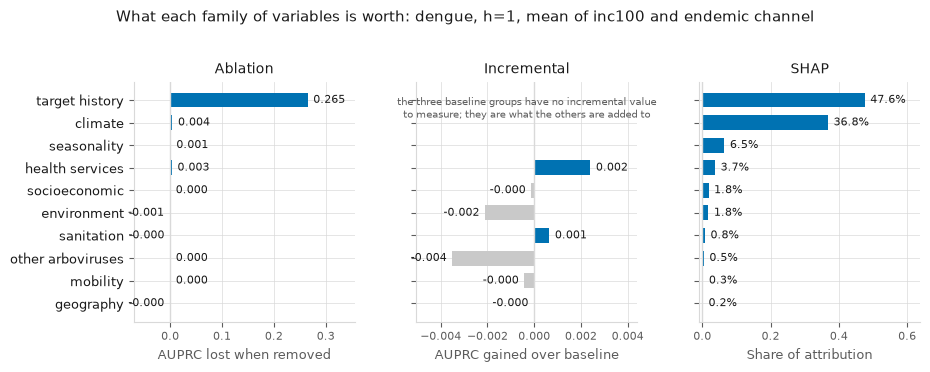

  Saved: figuras/ablacao_grupos.pdf and .png


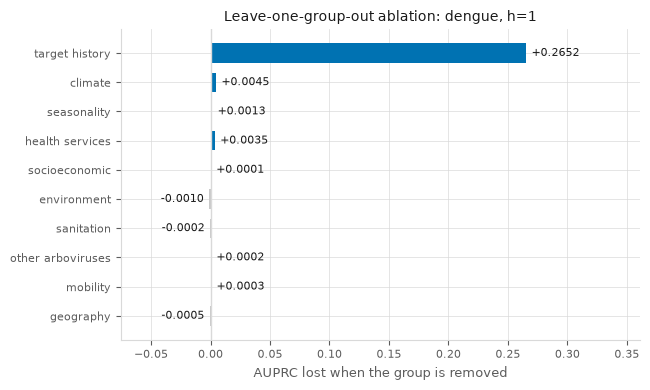

  Saved: figuras/incremental_grupos.pdf and .png


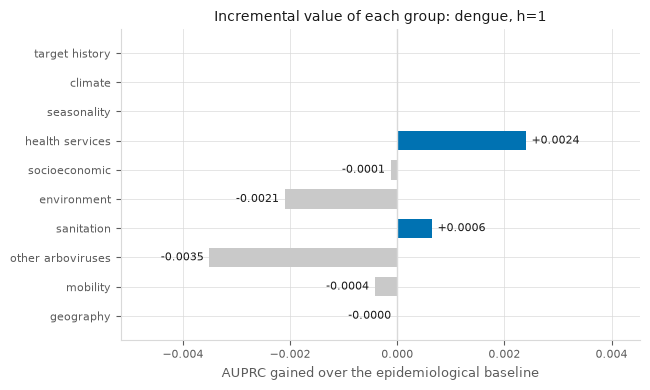

  Saved: figuras/shap_grupos.pdf and .png


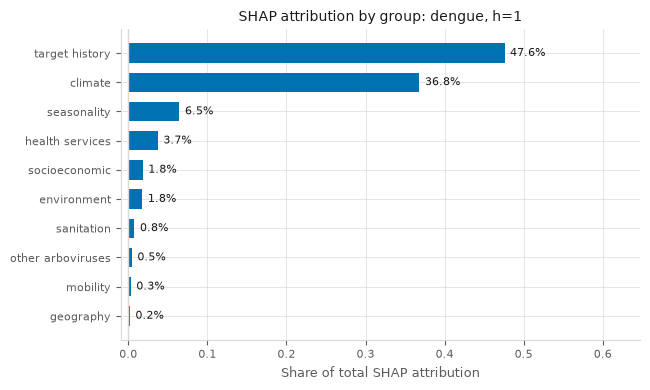

In [37]:
# --- The three readings, side by side ---
order = shap_summary.index.tolist()
panels = [
    ("Ablation", "delta_auprc", summary.reindex(order)["delta_auprc"],
     "AUPRC lost when removed"),
    ("Incremental", "gain_auprc",
     incr_summary.reindex(order)["gain_auprc"].fillna(np.nan),
     "AUPRC gained over baseline"),
    ("SHAP", "mean", shap_summary.reindex(order)["mean"],
     "Share of attribution"),
]

fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.6), sharey=True)
ypos = np.arange(len(order))
for ax, (title, _, series, xlabel) in zip(axes, panels):
    vals = series.values.astype(float)
    colours = [MODEL_COLORS["rf"] if not np.isnan(v) and v >= 0 else "#c9c9c9"
               for v in vals]
    ax.barh(ypos, np.nan_to_num(vals), color=colours, height=0.66, zorder=2)
    ax.axvline(0, color=GRID, linewidth=1)
    lo, hi = min(0.0, np.nanmin(vals)), np.nanmax(vals)
    span = hi - lo if hi > lo else 1.0
    for y, v in zip(ypos, vals):
        if np.isnan(v):
            continue
        ax.annotate(f"{v:.3f}" if title != "SHAP" else f"{100 * v:.1f}%",
                    (v, y), xytext=(4 if v >= 0 else -4, 0),
                    textcoords="offset points", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8, color=INK)
    # Only reserve room on the left when something actually goes negative.
    ax.set_xlim(lo - (0.26 * span if lo < 0 else 0.02 * span), hi + 0.34 * span)
    ax.set_title(title, fontsize=10, color=INK)
    style_axes(ax, xlabel=xlabel)
axes[1].annotate("the three baseline groups have no incremental value\n"
                 "to measure; they are what the others are added to",
                 (0.5, 0.94), xycoords="axes fraction", ha="center", va="top",
                 fontsize=7.5, color=MUTED)
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(order, fontsize=9, color=INK)
axes[0].invert_yaxis()
fig.suptitle(f"What each family of variables is worth: {DISEASE}, h={HORIZON}, "
             f"mean of inc100 and endemic channel", fontsize=11, color=INK, y=1.02)
fig.tight_layout(w_pad=2.4)   # keep neighbouring panels' end ticks apart
save_fig(fig, "feature_groups")
plt.show()

# The old repo shipped these as three separate figures; keep that granularity too.
for name, series, xlabel, title in [
        ("ablacao_grupos", summary.reindex(order)["delta_auprc"],
         "AUPRC lost when the group is removed",
         f"Leave-one-group-out ablation: {DISEASE}, h={HORIZON}"),
        ("incremental_grupos", incr_summary.reindex(order)["gain_auprc"],
         "AUPRC gained over the epidemiological baseline",
         f"Incremental value of each group: {DISEASE}, h={HORIZON}"),
        ("shap_grupos", shap_summary.reindex(order)["mean"],
         "Share of total SHAP attribution",
         f"SHAP attribution by group: {DISEASE}, h={HORIZON}")]:
    vals = series.values.astype(float)
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    ax.barh(ypos, np.nan_to_num(vals),
            color=[MODEL_COLORS["rf"] if not np.isnan(v) and v >= 0 else "#c9c9c9"
                   for v in vals], height=0.66, zorder=2)
    ax.axvline(0, color=GRID, linewidth=1)
    lo, hi = min(0.0, np.nanmin(vals)), np.nanmax(vals)
    span = hi - lo if hi > lo else 1.0
    for y, v in zip(ypos, vals):
        if np.isnan(v):
            continue
        ax.annotate(f"{100 * v:.1f}%" if name == "shap_grupos" else f"{v:+.4f}",
                    (v, y), xytext=(4 if v >= 0 else -4, 0),
                    textcoords="offset points", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8, color=INK)
    ax.set_xlim(lo - (0.28 * span if lo < 0 else 0.02 * span), hi + 0.36 * span)
    ax.set_yticks(ypos)
    ax.set_yticklabels(order, fontsize=9, color=INK)
    ax.invert_yaxis()
    style_axes(ax, xlabel=xlabel)
    ax.set_title(title, fontsize=10, color=INK)
    fig.tight_layout()
    save_fig(fig, name)
    plt.show()


## Section 17 — What is complete and what is not


In [38]:
print("Tables written:")
for path in sorted(TABLES_DIR.glob("*.csv")):
    print(f"  {path.name}")
print("\nFigures written:")
for path in sorted(FIG_DIR.glob("*.pdf")):
    print(f"  {path.name}")

print(f"\nTraining coverage: {len(results_on_disk)} of 96 combos on disk")
for disease in DISEASES:
    n = len(by_disease.get(disease, ()))
    print(f"  {disease:<12} {n:>2}/24 combos" + ("  COMPLETE" if n == 24 else ""))

# A missing combo is not automatically an unfinished one. Say which it is.
absent = [(d, f, h) for d in DISEASES for f in DEFINITIONS for h in range(1, 7)
          if (d, f, h) not in results_on_disk]
if absent:
    print(f"\n{len(absent)} combos have no result file:")
    for (d, f, h) in absent:
        pos = int(prevalence_table.loc[(d, f), "pos_all"]) \
              if (d, f) in prevalence_table.index else 0
        why = "no positive month in the whole series, so there was nothing to fit" \
              if pos == 0 else "positives exist — check the training log"
        print(f"  {d}/{f}/h{h}: {why}")

print("\nEvery table above is built only from what was on disk when this ran.")

Tables written:
  table1_cohort.csv
  table2_label_prevalence.csv
  table3_global_dengue_inc100.csv
  table4_disease_definition.csv
  table5_global_dengue_canal.csv
  table6_horizon_degradation.csv
  table_ablation_groups.csv
  table_alert_budget.csv
  table_by_municipality_size.csv
  table_by_season.csv
  table_calibration.csv
  table_evaluability.csv
  table_full_grid.csv
  table_incremental_groups.csv
  table_kappa_definitions.csv
  table_onset_vs_continuation.csv
  table_shap_groups.csv
  table_stability_by_year.csv

Figures written:
  ablacao_grupos.pdf
  alert_budget.pdf
  calibration.pdf
  feature_groups.pdf
  global_threshold.pdf
  horizon_by_disease.pdf
  horizon_degradation.pdf
  incremental_grupos.pdf
  kappa_heatmap.pdf
  onset_threshold.pdf
  onset_vs_continuation.pdf
  roc_pr_curves.pdf
  season_and_size.pdf
  shap_grupos.pdf
  stability_by_year.pdf
  threshold_tradeoff.pdf

Training coverage: 90 of 96 combos on disk
  dengue       24/24 combos  COMPLETE
  zika         24